# Perfiles de clientes que dejan el paquete Premium

**Data Mining en Economía y Finanzas — Entrega para Miranda**

Este notebook reconstruye de forma reproducible la población de bajas, estudia su comportamiento previo, identifica perfiles comercialmente diferentes y propone acciones preliminares respaldadas por evidencia descriptiva.

> **Consigna.** “Usted debe realizar un video presentación a Miranda que no puede exceder 5 minutos en donde le explique los perfiles de los clientes que se dan de baja de paquete premium y proponga acciones para revertirlo. Miranda no sabe (ni le interesa saber) sobre Ciencia de Datos pero está absolutamente convencida de las posibilidades que brinda la tecnología para tratar uno a uno a los clientes. Debe quedarle muy claro que el video a Miranda no es contarle lo mismo que Michelina pero en palabras de negocios, Miranda le está pidiendo los perfiles de los clientes que dejan de tener Paquete Premium e ideas de como evitarlo, ideas basadas en evidencia que debe salir de los datos. Debe quedarle claro que la tarea de un modelo predictivo es, situados dos meses antes, diferenciar a los que van a vivir de los que van a morir; Miranda le está pidiendo algo distinto: ‘en que se diferencian entre sí los que ya han muerto’.”

El objetivo no es predecir aquí quién abandonará. El análisis compara entre sí a clientes que ya dejaron el paquete y utiliza un Random Forest únicamente para construir una medida de similitud de comportamiento.

**Alcance temporal:** marzo–agosto de 2021. La ventana corta limita la interpretación de tendencias, estacionalidad y permanencia de la baja.


## 1. Resumen ejecutivo

El análisis identifica 3.977 bajas estrictas, 1.103 casos censurados a derecha y 23 intermitentes. Los casos del último mes se utilizan como sensibilidad; quienes desaparecen y regresan se mantienen separados.

La segmentación se construye sobre las 1.991 bajas estrictas con tres meses consecutivos de historia. La solución principal contiene cuatro perfiles: Vinculados multicanal (450), Digitales selectivos (541), Vinculados por nómina (104) y Desvinculación avanzada (896). Se utiliza una muestra balanceada de bajas y continuadores, cinco bosques con semillas declaradas y la proximidad promedio de Random Forest.

La solución es más estable que `k=3` dentro de los diagnósticos de semillas, pero muestra sensibilidad a la selección de continuadores y a incorporar censurados. Por ello se interpreta como una taxonomía útil y provisional. Las acciones propuestas son hipótesis para experimentar: el dataset no permite atribuir causalidad ni medir por sí solo la efectividad incremental de una campaña.


## 2. Diseño metodológico

El flujo separa cinco objetos que no deben confundirse:

1. **Etiqueta temporal:** `BAJA+1`, `BAJA+2` o `CONTINUA` para cada cliente-mes.
2. **Evento de ausencia:** transición de presente a ausente.
3. **Población principal:** salida sin retorno observado y con al menos dos meses posteriores.
4. **Representación supervisada:** proximidad entre bajas según bosques que distinguen bajas de continuadores comparables.
5. **Segmentación:** clustering jerárquico sobre esa distancia; no es una predicción ni una estimación causal.

La guía auxiliar se utiliza para organizar hipótesis. La definición de la consigna proviene del libro de la materia. El método temporal sigue `z402_Feature_Engineering_en_SQL.ipynb`; la representación mediante bosque toma como antecedente `z501_cluster_rf.py`, pero utiliza proximidad de Random Forest y clustering jerárquico, en línea con el capítulo 28 del libro.


## 3. Configuración 

Esta sección centraliza imports, rutas, semillas, colores y funciones. 

In [1]:
from pathlib import Path
import os
import platform
import hashlib
import warnings

import duckdb
import matplotlib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import scipy
import seaborn as sns
import sklearn

from IPython.display import Markdown, display
from matplotlib.patches import FancyBboxPatch
from scipy.cluster.hierarchy import dendrogram, fcluster, linkage
from scipy.optimize import linear_sum_assignment
from scipy.sparse import csr_matrix
from scipy.spatial.distance import squareform
from sklearn.ensemble import RandomForestClassifier
from sklearn.impute import SimpleImputer
from sklearn.metrics import (
    adjusted_rand_score,
    balanced_accuracy_score,
    classification_report,
    f1_score,
    silhouette_score,
)
from sklearn.model_selection import LeaveOneGroupOut, cross_val_predict
from sklearn.pipeline import Pipeline

PROJECT_DIR = Path.cwd().resolve()
OUTPUT_DIR = PROJECT_DIR / "eda_limpio_outputs"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

RF_SEEDS = [214363, 42, 2026, 12345, 987654]
CONTROL_SEED = 214363
CONTROL_SENSITIVITY_SEEDS = [9031, 17539]
K_FINAL = 4
N_TREES = 300
MIN_SAMPLES_LEAF = 50

PROFILE_ORDER = [
    "Vinculados multicanal",
    "Digitales selectivos",
    "Vinculados por nómina",
    "Desvinculación avanzada",
]
PROFILE_COLORS = {
    "Vinculados multicanal": "#2F6B9A",
    "Digitales selectivos": "#6C8EBF",
    "Vinculados por nómina": "#2A9D8F",
    "Desvinculación avanzada": "#D97732",
}

sns.set_theme(style="whitegrid", context="notebook")
pd.set_option("display.max_columns", 120)
pd.set_option("display.float_format", lambda x: f"{x:,.2f}")

dataset_candidates = []
if os.environ.get("DMEYF_DATASET"):
    dataset_candidates.append(Path(os.environ["DMEYF_DATASET"]).expanduser())
dataset_candidates.extend([
    PROJECT_DIR / "data" / "competencia_01_crudo.csv",
    Path(
        "/Users/manuelmarasco/Library/CloudStorage/"
        "GoogleDrive-hola@manuelmarasco.com/Mi unidad/"
        "DMEyF/2026/notebooks/data/competencia_01_crudo.csv"
    ),
])

DATASET_PATH = next((p for p in dataset_candidates if p.exists()), None)
if DATASET_PATH is None:
    raise FileNotFoundError(
        "No se encontró competencia_01_crudo.csv. Definir DMEYF_DATASET "
        "o ubicarlo en ./data/."
    )

versions = pd.DataFrame({
    "componente": ["Python", "DuckDB", "pandas", "NumPy", "SciPy", "scikit-learn", "Matplotlib"],
    "versión": [
        platform.python_version(), duckdb.__version__, pd.__version__, np.__version__,
        scipy.__version__, sklearn.__version__, matplotlib.__version__,
    ],
})
display(versions)
print("Dataset:", DATASET_PATH)
print("Salidas:", OUTPUT_DIR)


,componente,versión
0,Python,3.9.6
1,DuckDB,1.4.5
2,pandas,2.3.3
3,NumPy,2.0.2
4,SciPy,1.13.1
5,scikit-learn,1.6.1
6,Matplotlib,3.9.4


Dataset: /Users/manuelmarasco/Library/CloudStorage/GoogleDrive-hola@manuelmarasco.com/Mi unidad/DMEyF/2026/notebooks/data/competencia_01_crudo.csv
Salidas: /Users/manuelmarasco/Desktop/dmeyf402/eda_limpio_outputs


## 4. Carga y auditoría inicial

Se verifica la unidad de observación, el identificador y el período antes de definir la baja. El dataset crudo se lee sin modificar y se copia a una base DuckDB en memoria.


In [2]:
con = duckdb.connect(database=":memory:")
con.execute("PRAGMA disable_progress_bar")
con.execute("SET preserve_insertion_order = false")
con.execute(
    """
    CREATE TABLE raw AS
    SELECT * REPLACE (
        CAST(numero_de_cliente AS BIGINT) AS numero_de_cliente,
        CAST(foto_mes AS BIGINT) AS foto_mes
    )
    FROM read_csv_auto(?, sample_size=-1)
    """,
    [str(DATASET_PATH)],
)

auditoria_inicial = con.execute(
    """
    SELECT
        COUNT(*) AS filas,
        COUNT(DISTINCT numero_de_cliente) AS clientes,
        COUNT(DISTINCT foto_mes) AS meses,
        MIN(foto_mes) AS primer_mes,
        MAX(foto_mes) AS ultimo_mes,
        COUNT(*) - COUNT(DISTINCT (numero_de_cliente, foto_mes)) AS duplicados_cliente_mes,
        COUNT(*) FILTER (WHERE numero_de_cliente IS NULL) AS ids_nulos
    FROM raw
    """
).df()

assert auditoria_inicial.loc[0, "duplicados_cliente_mes"] == 0
assert auditoria_inicial.loc[0, "ids_nulos"] == 0
display(auditoria_inicial)

filas_por_mes = con.execute(
    """
    SELECT foto_mes, COUNT(*) AS filas, COUNT(DISTINCT numero_de_cliente) AS clientes
    FROM raw GROUP BY foto_mes ORDER BY foto_mes
    """
).df()
display(filas_por_mes)


,filas,clientes,meses,primer_mes,ultimo_mes,duplicados_cliente_mes,ids_nulos
0,983061,169727,6,202103,202108,0,0


,foto_mes,filas,clientes
0,202103,162900,162900
1,202104,163284,163284
2,202105,163768,163768
3,202106,164114,164114
4,202107,164348,164348
5,202108,164647,164647


## 5. Definición de la baja y de las poblaciones

Se construye un panel completo cliente-mes. Un evento comienza cuando un cliente presente pasa a estar ausente el mes siguiente.

- **Estricta:** no retorna y existen al menos dos meses posteriores observables.
- **Censurada a derecha:** sólo se observa un mes posterior, no puede confirmarse permanencia.
- **Intermitente:** reaparece dentro de la ventana.

Esta definición evita contar BAJA+1 y BAJA+2 como dos abandonos diferentes.


In [3]:
con.execute(
    """
    CREATE TABLE calendario AS
    SELECT foto_mes, ROW_NUMBER() OVER (ORDER BY foto_mes) AS indice_mes
    FROM (SELECT DISTINCT foto_mes FROM raw)
    ORDER BY foto_mes;

    CREATE TABLE panel_presencia AS
    WITH clientes AS (SELECT DISTINCT numero_de_cliente FROM raw)
    SELECT
        c.numero_de_cliente,
        m.foto_mes,
        m.indice_mes,
        CASE WHEN r.numero_de_cliente IS NULL THEN 0 ELSE 1 END AS presente
    FROM clientes c
    CROSS JOIN calendario m
    LEFT JOIN raw r USING (numero_de_cliente, foto_mes);

    CREATE TABLE eventos_baja AS
    WITH secuencia AS (
        SELECT
            *,
            LEAD(foto_mes, 1) OVER w AS primer_mes_ausente,
            LEAD(presente, 1) OVER w AS presente_siguiente,
            COALESCE(
                MAX(presente) OVER (
                    PARTITION BY numero_de_cliente ORDER BY foto_mes
                    ROWS BETWEEN 2 FOLLOWING AND UNBOUNDED FOLLOWING
                ), 0
            ) AS vuelve_mas_adelante,
            COUNT(*) OVER (
                PARTITION BY numero_de_cliente ORDER BY foto_mes
                ROWS BETWEEN 1 FOLLOWING AND UNBOUNDED FOLLOWING
            ) AS meses_observables_despues
        FROM panel_presencia
        WINDOW w AS (PARTITION BY numero_de_cliente ORDER BY foto_mes)
    ),
    transiciones AS (
        SELECT
            numero_de_cliente,
            foto_mes AS ultimo_mes_activo,
            primer_mes_ausente,
            vuelve_mas_adelante,
            meses_observables_despues
        FROM secuencia
        WHERE presente = 1 AND presente_siguiente = 0
    )
    SELECT
        *,
        ROW_NUMBER() OVER (
            PARTITION BY numero_de_cliente ORDER BY ultimo_mes_activo
        ) AS numero_evento,
        CASE
            WHEN vuelve_mas_adelante = 1 THEN 'intermitente'
            WHEN meses_observables_despues = 1 THEN 'censurada'
            ELSE 'estricta'
        END AS poblacion
    FROM transiciones;
    """
)

auditoria_eventos = con.execute(
    """
    SELECT
        poblacion,
        COUNT(*) AS eventos,
        COUNT(DISTINCT numero_de_cliente) AS clientes,
        COUNT(*) - COUNT(DISTINCT (numero_de_cliente, numero_evento)) AS claves_duplicadas
    FROM eventos_baja
    GROUP BY poblacion
    ORDER BY poblacion
    """
).df()

assert auditoria_eventos["claves_duplicadas"].sum() == 0
assert con.execute(
    "SELECT COUNT(*) FROM (SELECT numero_de_cliente FROM eventos_baja GROUP BY 1 HAVING COUNT(*) > 1)"
).fetchone()[0] == 0

display(auditoria_eventos)

eventos_por_mes = con.execute(
    """
    SELECT poblacion, ultimo_mes_activo, COUNT(*) AS clientes
    FROM eventos_baja GROUP BY 1,2 ORDER BY 1,2
    """
).df()
display(eventos_por_mes)


,poblacion,eventos,clientes,claves_duplicadas
0,censurada,1103,1103,0
1,estricta,3977,3977,0
2,intermitente,23,23,0


,poblacion,ultimo_mes_activo,clientes
0,censurada,202107,1103
1,estricta,202103,1013
2,estricta,202104,955
3,estricta,202105,1138
4,estricta,202106,871
5,intermitente,202103,6
6,intermitente,202104,9
7,intermitente,202105,5
8,intermitente,202106,3


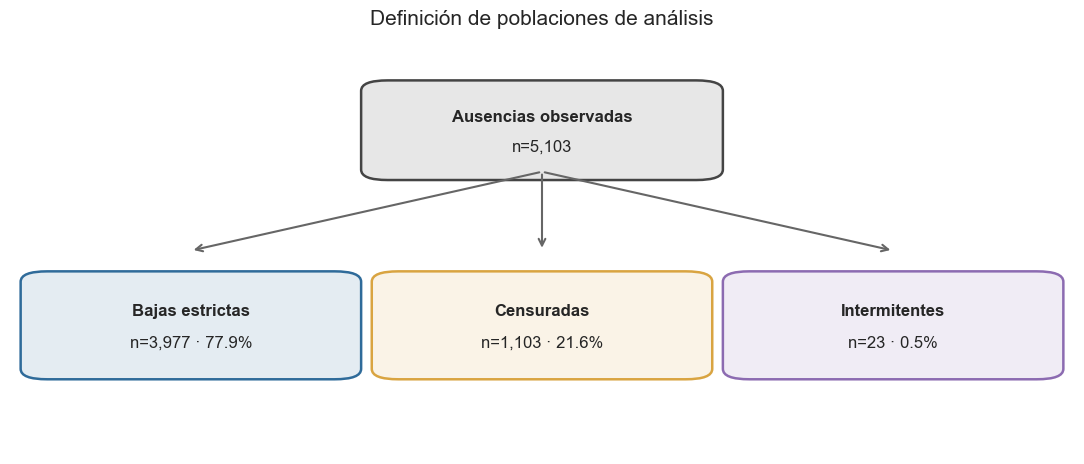

In [4]:
conteos_eventos = auditoria_eventos.set_index("poblacion")["clientes"].to_dict()

fig, ax = plt.subplots(figsize=(11, 4.8))
ax.axis("off")

def caja(ax, x, y, w, h, titulo, detalle, color):
    patch = FancyBboxPatch(
        (x, y), w, h, boxstyle="round,pad=0.02,rounding_size=0.025",
        linewidth=1.8, edgecolor=color, facecolor=color + "20",
        transform=ax.transAxes,
    )
    ax.add_patch(patch)
    ax.text(x + w/2, y + h*0.65, titulo, ha="center", va="center", weight="bold", transform=ax.transAxes)
    ax.text(x + w/2, y + h*0.30, detalle, ha="center", va="center", transform=ax.transAxes)

total_eventos = sum(conteos_eventos.values())
caja(ax, 0.35, 0.68, 0.30, 0.20, "Ausencias observadas", f"n={total_eventos:,}", "#444444")
destinos = [
    (0.03, "Bajas estrictas", "estricta", "#2F6B9A"),
    (0.36, "Censuradas", "censurada", "#D9A441"),
    (0.69, "Intermitentes", "intermitente", "#8C6BB1"),
]
for x, titulo, clave, color in destinos:
    ax.annotate("", xy=(x+0.14, 0.49), xytext=(0.50, 0.68), xycoords=ax.transAxes,
                arrowprops=dict(arrowstyle="->", color="#666666", lw=1.5))
    n = int(conteos_eventos[clave])
    caja(ax, x, 0.20, 0.28, 0.22, titulo, f"n={n:,} · {100*n/total_eventos:.1f}%", color)
ax.set_title("Definición de poblaciones de análisis", fontsize=15, pad=10)
fig.tight_layout()
fig.savefig(OUTPUT_DIR / "01_poblaciones.png", dpi=160, bbox_inches="tight")
plt.show()


**Interpretación.** La población principal excluye tanto la censura del final de la ventana como las ausencias transitorias. “Baja estricta” significa ausencia sostenida durante el seguimiento disponible, no una cancelación contractual demostrada. Los censurados se incorporarán como sensibilidad y los intermitentes se estudiarán por separado.


## 6. Clase temporal y relación entre BAJA+1 y BAJA+2

La clase ternaria se calcula sobre el panel completo y se incorpora únicamente a las filas observadas. `BAJA+1` y `BAJA+2` son estados en meses diferentes de una misma trayectoria; no son dos tipos de cliente.


In [5]:
con.execute(
    """
    CREATE TABLE panel_etiquetado AS
    SELECT
        *,
        LEAD(presente, 1) OVER w AS presente_mas_1,
        LEAD(presente, 2) OVER w AS presente_mas_2,
        CASE
            WHEN presente = 1 AND LEAD(presente, 1) OVER w = 0 THEN 'BAJA+1'
            WHEN presente = 1 AND LEAD(presente, 1) OVER w = 1
                              AND LEAD(presente, 2) OVER w = 0 THEN 'BAJA+2'
            WHEN presente = 1 AND LEAD(presente, 1) OVER w = 1
                              AND LEAD(presente, 2) OVER w = 1 THEN 'CONTINUA'
            ELSE NULL
        END AS clase_ternaria
    FROM panel_presencia
    WINDOW w AS (PARTITION BY numero_de_cliente ORDER BY foto_mes);

    CREATE TABLE datos_etiquetados AS
    SELECT r.*, p.indice_mes, p.clase_ternaria
    FROM raw r
    JOIN panel_etiquetado p USING (numero_de_cliente, foto_mes);
    """
)

clases_mes = con.execute(
    """
    SELECT foto_mes, COALESCE(clase_ternaria, 'SIN_ETIQUETA') AS clase, COUNT(*) AS clientes
    FROM datos_etiquetados GROUP BY 1,2 ORDER BY 1,2
    """
).df()
display(clases_mes)

relacion_bajas = con.execute(
    """
    WITH marcas AS (
        SELECT numero_de_cliente,
               MAX(clase_ternaria='BAJA+1')::INT AS baja_1,
               MAX(clase_ternaria='BAJA+2')::INT AS baja_2
        FROM datos_etiquetados GROUP BY numero_de_cliente
    )
    SELECT baja_1, baja_2, COUNT(*) AS clientes
    FROM marcas GROUP BY 1,2 ORDER BY 1,2
    """
).df()
display(relacion_bajas)


,foto_mes,clase,clientes
0,202103,BAJA+1,1019
1,202103,BAJA+2,960
2,202103,CONTINUA,160921
3,202104,BAJA+1,964
4,202104,BAJA+2,1139
5,202104,CONTINUA,161181
6,202105,BAJA+1,1143
7,202105,BAJA+2,870
8,202105,CONTINUA,161755
9,202106,BAJA+1,874


,baja_1,baja_2,clientes
0,0,0,162132
1,1,0,1036
2,1,1,4067
3,<NA>,<NA>,2492


## 7. Calidad de datos y semántica de los nulos

Los nulos no se reemplazan masivamente por cero. Se resumen por columna y se verifica si se concentran en familias específicas. La ausencia de producto, la ausencia de uso y la ausencia de información se mantienen conceptualmente separadas.


In [6]:
columnas_raw = con.execute("PRAGMA table_info('raw')").df()["name"].tolist()
expresiones_nulos = ", ".join(
    f"SUM(\"{c}\" IS NULL)::BIGINT AS \"{c}\"" for c in columnas_raw
)
nulos_serie = con.execute(f"SELECT {expresiones_nulos} FROM raw").df().iloc[0]
nulos = (
    nulos_serie[nulos_serie > 0]
    .rename("nulos")
    .to_frame()
    .assign(porcentaje=lambda t: 100 * t["nulos"] / int(auditoria_inicial.loc[0, "filas"]))
    .sort_values("porcentaje", ascending=False)
)

print(f"Columnas con nulos: {len(nulos)} de {len(columnas_raw)}")
es_familia_tarjeta = lambda c: str(c).startswith(("Visa_", "Master_", "mtarjeta_"))
print("Todas pertenecen a la familia de tarjetas:", all(es_familia_tarjeta(c) for c in nulos.index))
display(nulos.head(20).round(2))

auditoria_tarjetas = con.execute(
    """
    SELECT tarjeta, tenencia, n, limite_nulo, consumo_nulo, cantidad_consumos_nula
    FROM (
        SELECT 'Master' AS tarjeta,
               CASE WHEN ctarjeta_master > 0 THEN 'producto informado' ELSE 'sin producto informado' END AS tenencia,
               COUNT(*) AS n,
               SUM(Master_mlimitecompra IS NULL) AS limite_nulo,
               SUM(Master_mconsumototal IS NULL) AS consumo_nulo,
               SUM(Master_cconsumos IS NULL) AS cantidad_consumos_nula
        FROM raw GROUP BY 2
        UNION ALL
        SELECT 'Visa',
               CASE WHEN ctarjeta_visa > 0 THEN 'producto informado' ELSE 'sin producto informado' END,
               COUNT(*), SUM(Visa_mlimitecompra IS NULL), SUM(Visa_mconsumototal IS NULL),
               SUM(Visa_cconsumos IS NULL)
        FROM raw GROUP BY 2
    ) ORDER BY tarjeta, tenencia
    """
).df()
display(auditoria_tarjetas)


Columnas con nulos: 46 de 154
Todas pertenecen a la familia de tarjetas: True


,nulos,porcentaje
Master_Finiciomora,978240,99.51
Visa_Finiciomora,969739,98.64
Master_mpagospesos,579470,58.95
Master_mconsumospesos,579470,58.95
Master_cconsumos,579470,58.95
Master_cadelantosefectivo,579470,58.95
Master_madelantodolares,579470,58.95
Master_madelantopesos,579470,58.95
Master_mconsumosdolares,579470,58.95
Master_mconsumototal,579470,58.95


,tarjeta,tenencia,n,limite_nulo,consumo_nulo,cantidad_consumos_nula
0,Master,producto informado,879794,0.00,"478,920.00","478,920.00"
1,Master,sin producto informado,103267,"99,644.00","100,550.00","100,550.00"
2,Visa,producto informado,931364,0.00,"80,217.00","80,217.00"
3,Visa,sin producto informado,51697,"47,186.00","47,543.00","47,543.00"


In [7]:
tipos = con.execute("PRAGMA table_info('raw')").df()
columnas_double = tipos.loc[tipos["type"].str.contains("DOUBLE|FLOAT|DECIMAL", regex=True), "name"].tolist()
expr_inf = ", ".join(
    f"SUM(CASE WHEN NOT isfinite(\"{c}\") THEN 1 ELSE 0 END)::BIGINT AS \"{c}\""
    for c in columnas_double
)
infinitos = con.execute(f"SELECT {expr_inf} FROM raw").df().iloc[0]

auditoria_signos = con.execute(
    """
    SELECT
        SUM(mcuentas_saldo < 0) AS saldos_negativos,
        SUM(mrentabilidad < 0) AS rentabilidades_negativas,
        SUM(mcomisiones_mantenimiento < 0) AS mantenimientos_negativos,
        SUM(mcomisiones_otras < 0) AS otras_comisiones_negativas
    FROM raw
    """
).df()

print("Valores infinitos:", int(infinitos.sum()))
display(auditoria_signos)

variables_monetarias_mes = con.execute(
    """
    SELECT foto_mes,
           MEDIAN(mcuentas_saldo) AS saldo_mediano,
           MEDIAN(mrentabilidad) AS rentabilidad_mediana,
           MEDIAN(mpayroll) FILTER (WHERE mpayroll > 0) AS payroll_positivo_mediano,
           AVG(CAST(cliente_vip AS DOUBLE)) * 100 AS porcentaje_vip
    FROM raw GROUP BY foto_mes ORDER BY foto_mes
    """
).df()
display(variables_monetarias_mes.round(2))


Valores infinitos: 0


,saldos_negativos,rentabilidades_negativas,mantenimientos_negativos,otras_comisiones_negativas
0,"191,268.00","227,560.00","13,762.00","17,213.00"


,foto_mes,saldo_mediano,rentabilidad_mediana,payroll_positivo_mediano,porcentaje_vip
0,202103,"33,708.51","1,250.06","98,080.32",0.26
1,202104,"32,804.15","1,125.14","101,399.98",0.26
2,202105,"32,565.80","1,221.78","105,773.49",0.27
3,202106,"47,801.62","1,360.57","156,529.81",0.56
4,202107,"48,598.77","1,702.70","117,300.00",0.27
5,202108,"38,153.05","1,854.70","119,223.96",0.28


**Decisiones de calidad.** Se preservan los nulos originales de tarjetas. Las variables administrativas, fechas, estados y códigos de Visa/Master no se entregarán al bosque. Las variables monetarias se conservan en sus unidades originales y no se suman importes identificados como pesos y dólares. Los cambios mensuales muestran estacionalidad —en particular payroll en junio—, por lo que los controles se balancean dentro del mismo mes y la limitación se mantiene explícita.


## 8. Comparación descriptiva: bajas y continuadores

Esta comparación responde si, en el último mes activo, quienes dejan el paquete muestran menor vinculación o uso que clientes que continúan. Es una asociación descriptiva; no identifica causas.


In [8]:
con.execute(
    """
    CREATE TABLE comparacion_t0 AS
    SELECT
        e.numero_de_cliente, e.ultimo_mes_activo AS foto_mes_ancla,
        'Baja estricta' AS grupo, r.* EXCLUDE (numero_de_cliente, foto_mes)
    FROM eventos_baja e
    JOIN raw r ON e.numero_de_cliente=r.numero_de_cliente AND e.ultimo_mes_activo=r.foto_mes
    WHERE e.poblacion='estricta'
    UNION ALL BY NAME
    SELECT
        d.numero_de_cliente, d.foto_mes AS foto_mes_ancla,
        'Continúa' AS grupo, d.* EXCLUDE (numero_de_cliente, foto_mes, indice_mes, clase_ternaria)
    FROM datos_etiquetados d
    WHERE d.clase_ternaria='CONTINUA';
    """
)

comparacion_t0 = con.execute(
    """
    SELECT
        foto_mes_ancla, grupo, COUNT(*) AS clientes,
        MEDIAN(cproductos) AS productos_mediana,
        MEDIAN(ctrx_quarter) AS transacciones_mediana,
        AVG(CAST(cpayroll_trx > 0 AS DOUBLE)) * 100 AS porcentaje_payroll,
        AVG(CAST((ctarjeta_visa_transacciones + ctarjeta_master_transacciones) > 0 AS DOUBLE)) * 100 AS porcentaje_usa_tarjeta,
        AVG(CAST((chomebanking_transacciones + cmobile_app_trx) > 0 AS DOUBLE)) * 100 AS porcentaje_digital,
        AVG(CAST(ctransferencias_emitidas > 0 AS DOUBLE)) * 100 AS porcentaje_transfiere,
        MEDIAN(mcuentas_saldo) AS saldo_mediano,
        MEDIAN(mrentabilidad) AS rentabilidad_mediana
    FROM comparacion_t0
    GROUP BY 1,2 ORDER BY 1,2
    """
).df()
display(comparacion_t0.round(2))


,foto_mes_ancla,grupo,clientes,productos_mediana,transacciones_mediana,porcentaje_payroll,porcentaje_usa_tarjeta,porcentaje_digital,porcentaje_transfiere,saldo_mediano,rentabilidad_mediana
0,202103,Baja estricta,1013,6.00,18.00,4.24,43.83,68.61,22.61,"-1,751.24","1,755.33"
1,202103,Continúa,160921,7.00,105.00,54.63,86.69,94.28,60.94,"35,036.93","1,239.26"
2,202104,Baja estricta,955,6.00,18.00,4.61,43.87,69.21,23.56,"-1,935.35","1,733.09"
3,202104,Continúa,161181,7.00,106.00,54.72,86.98,94.30,60.36,"34,084.74","1,112.37"
4,202105,Baja estricta,1138,6.00,16.00,5.80,38.05,64.59,18.80,"-2,156.07","1,823.28"
5,202105,Continúa,161755,7.00,106.00,55.56,86.98,94.45,60.66,"33,728.59","1,211.22"
6,202106,Baja estricta,871,6.00,23.00,5.74,48.34,75.43,25.37,"-1,910.55","1,769.30"
7,202106,Continúa,162142,7.00,106.00,55.86,87.45,94.45,61.95,"49,157.00","1,350.80"


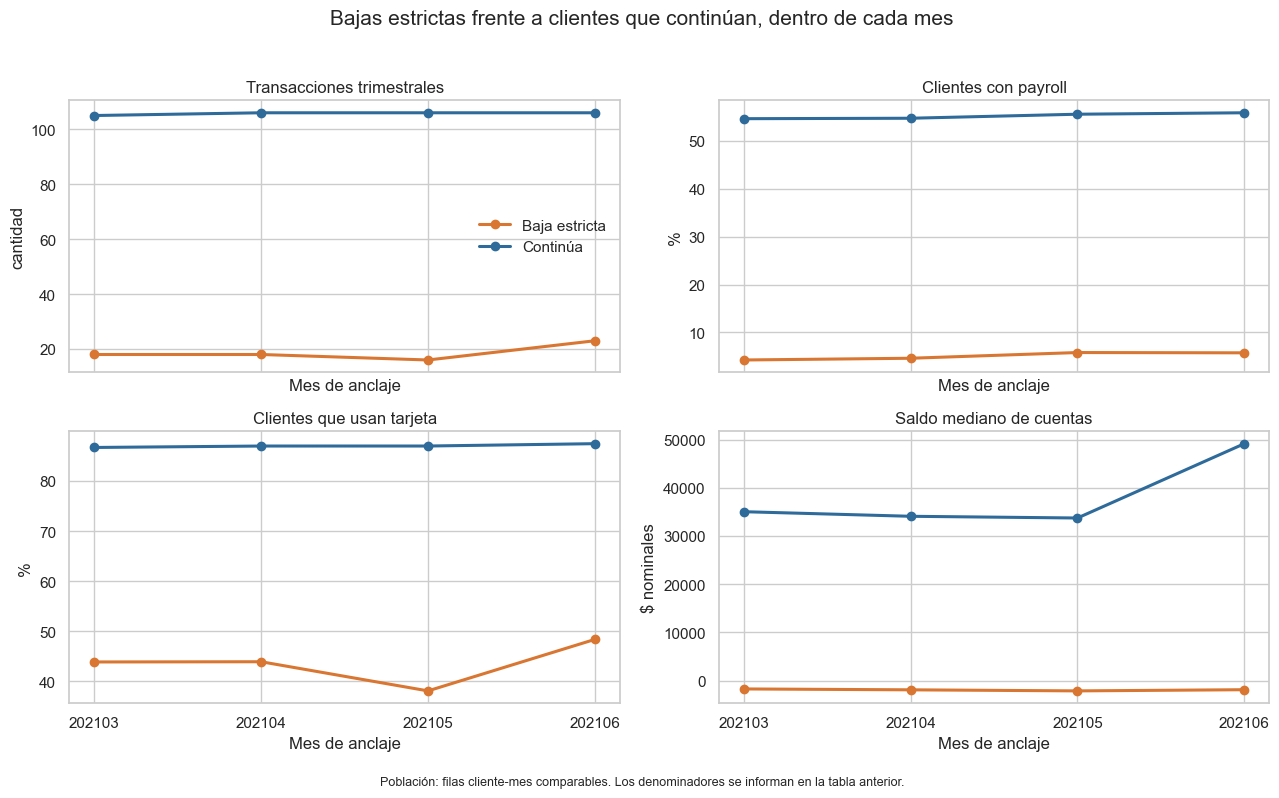

In [9]:
fig, axes = plt.subplots(2, 2, figsize=(13, 8), sharex=True)
metricas = [
    ("transacciones_mediana", "Transacciones trimestrales", "cantidad"),
    ("porcentaje_payroll", "Clientes con payroll", "%"),
    ("porcentaje_usa_tarjeta", "Clientes que usan tarjeta", "%"),
    ("saldo_mediano", "Saldo mediano de cuentas", "$ nominales"),
]
for ax, (col, titulo, unidad) in zip(axes.ravel(), metricas):
    for grupo, color in [("Baja estricta", "#D97732"), ("Continúa", "#2F6B9A")]:
        d = comparacion_t0[comparacion_t0["grupo"] == grupo]
        ax.plot(d["foto_mes_ancla"].astype(str), d[col], marker="o", lw=2.2, label=grupo, color=color)
    ax.set_title(titulo)
    ax.set_ylabel(unidad)
    ax.set_xlabel("Mes de anclaje")
axes[0, 0].legend(frameon=False)
fig.suptitle("Bajas estrictas frente a clientes que continúan, dentro de cada mes", fontsize=15)
fig.text(0.5, 0.01, "Población: filas cliente-mes comparables. Los denominadores se informan en la tabla anterior.", ha="center", fontsize=9)
fig.tight_layout(rect=[0, 0.03, 1, 0.96])
fig.savefig(OUTPUT_DIR / "02_bajas_vs_continuadores.png", dpi=160, bbox_inches="tight")
plt.show()


**Conclusión descriptiva.** Las bajas llegan a `t0` con menos actividad, menor uso de tarjetas, menor presencia de payroll y una posición de saldo más débil. La persistencia del patrón dentro de cada mes reduce el riesgo de confundirlo con inflación o calendario, pero no demuestra que alguno de esos factores cause la salida.


## 9. Feature engineering temporal

Las features se calculan primero sobre todo el panel de observaciones activas y recién después se selecciona `t0`. Todas las ventanas se particionan por cliente y utilizan el mes actual y los dos anteriores. No se utiliza `LEAD` dentro de las features.


In [10]:
campos_temporales = [
    "ctrx_quarter", "mcuentas_saldo", "cproductos", "mrentabilidad",
    "mcomisiones_mantenimiento", "mpayroll", "tarjetas_consumo",
    "mtransferencias_emitidas",
]
campos_eventos = [
    "cpayroll_trx", "tarjetas_cantidad", "tarjetas_transacciones",
    "debitos_automaticos", "pagos_servicios", "transacciones_digitales",
    "cantidad_creditos", "cantidad_inversiones", "cantidad_seguros",
]

derivadas = []
for campo in campos_temporales:
    derivadas.extend([
        f"LAG({campo},1) OVER w AS {campo}_lag_1",
        f"LAG({campo},2) OVER w AS {campo}_lag_2",
        f"{campo}-LAG({campo},1) OVER w AS {campo}_delta_1",
        f"{campo}-LAG({campo},2) OVER w AS {campo}_delta_2",
        f"AVG({campo}) OVER w3 AS {campo}_media_3",
        f"MIN({campo}) OVER w3 AS {campo}_minimo_3",
        f"MAX({campo}) OVER w3 AS {campo}_maximo_3",
        f"MAX({campo}) OVER w3-MIN({campo}) OVER w3 AS {campo}_rango_3",
        f"REGR_SLOPE({campo},indice_mes) OVER w3 AS {campo}_pendiente_3",
    ])
for campo in campos_eventos:
    derivadas.extend([
        f"LAG({campo},1) OVER w AS {campo}_lag_1",
        f"LAG({campo},2) OVER w AS {campo}_lag_2",
        f"{campo}-LAG({campo},1) OVER w AS {campo}_delta_1",
        f"{campo}-LAG({campo},2) OVER w AS {campo}_delta_2",
        f"CASE WHEN {campo}=0 AND GREATEST(LAG({campo},1) OVER w,LAG({campo},2) OVER w)>0 THEN 1 ELSE 0 END AS abandono_{campo}_3m",
    ])

sql_derivadas = ",\n".join(derivadas)
con.execute(
    f"""
    CREATE TABLE fe_panel AS
    WITH base AS (
        SELECT
            d.*,
            d.ctarjeta_visa + d.ctarjeta_master AS tarjetas_cantidad,
            d.ctarjeta_visa_transacciones + d.ctarjeta_master_transacciones AS tarjetas_transacciones,
            d.mtarjeta_visa_consumo + d.mtarjeta_master_consumo AS tarjetas_consumo,
            d.ccuenta_debitos_automaticos + d.ctarjeta_visa_debitos_automaticos
                + d.ctarjeta_master_debitos_automaticos AS debitos_automaticos,
            d.cpagodeservicios + d.cpagomiscuentas AS pagos_servicios,
            d.chomebanking_transacciones + d.cmobile_app_trx AS transacciones_digitales,
            d.cprestamos_personales + d.cprestamos_prendarios
                + d.cprestamos_hipotecarios AS cantidad_creditos,
            d.cplazo_fijo + d.cinversion1 + d.cinversion2 + d.cforex AS cantidad_inversiones,
            d.cseguro_vida + d.cseguro_auto + d.cseguro_vivienda
                + d.cseguro_accidentes_personales AS cantidad_seguros
        FROM datos_etiquetados d
    )
    SELECT
        base.*,
        COUNT(*) OVER w AS observaciones_hasta_mes,
        indice_mes-LAG(indice_mes,1) OVER w AS salto_1,
        indice_mes-LAG(indice_mes,2) OVER w AS salto_2,
        {sql_derivadas}
    FROM base
    WINDOW
        w AS (PARTITION BY numero_de_cliente ORDER BY foto_mes),
        w3 AS (PARTITION BY numero_de_cliente ORDER BY foto_mes ROWS BETWEEN 2 PRECEDING AND CURRENT ROW)
    """
)

auditoria_fe = con.execute(
    """
    SELECT
        COUNT(*) AS filas,
        COUNT(DISTINCT (numero_de_cliente,foto_mes)) AS claves,
        COUNT(*) FILTER (WHERE observaciones_hasta_mes>=3 AND salto_1=1 AND salto_2=2) AS filas_con_3m_consecutivos
    FROM fe_panel
    """
).df()
assert auditoria_fe.loc[0, "filas"] == auditoria_fe.loc[0, "claves"]
display(auditoria_fe)


,filas,claves,filas_con_3m_consecutivos
0,983061,983061,645999


## 10. Muestra de referencia

La segmentación se estima sobre bajas con tres meses consecutivos. Para cada mes de anclaje se selecciona igual cantidad de continuadores, sin repetir clientes entre mayo y junio. La selección de controles es determinística y puede variarse para medir sensibilidad.


In [11]:
strict_all = con.execute(
    """
    SELECT
        e.numero_evento, e.ultimo_mes_activo AS foto_mes_ancla,
        e.primer_mes_ausente, e.poblacion,
        f.* EXCLUDE (foto_mes)
    FROM eventos_baja e
    JOIN fe_panel f ON e.numero_de_cliente=f.numero_de_cliente
                   AND e.ultimo_mes_activo=f.foto_mes
    WHERE e.poblacion='estricta'
    ORDER BY foto_mes_ancla, f.numero_de_cliente
    """
).df()

strict_all["historia_3m_completa"] = (
    (strict_all["observaciones_hasta_mes"] >= 3)
    & (strict_all["salto_1"] == 1)
    & (strict_all["salto_2"] == 2)
).astype(int)
strict_complete = strict_all[strict_all["historia_3m_completa"] == 1].copy()

control_candidates = con.execute(
    """
    SELECT *
    FROM fe_panel
    WHERE foto_mes IN (202105,202106)
      AND clase_ternaria='CONTINUA'
      AND observaciones_hasta_mes>=3
      AND salto_1=1 AND salto_2=2
    ORDER BY foto_mes, numero_de_cliente
    """
).df()

targets_mes = strict_complete.groupby("foto_mes_ancla").size().to_dict()

def seleccionar_controles(seed):
    rng = np.random.default_rng(seed)
    candidatos = control_candidates.copy()
    candidatos["_orden"] = rng.random(len(candidatos))
    elegidos = []
    usados = set()
    for mes in sorted(targets_mes):
        d = candidatos[(candidatos["foto_mes"] == mes) & (~candidatos["numero_de_cliente"].isin(usados))]
        d = d.nsmallest(int(targets_mes[mes]), "_orden").drop(columns="_orden")
        elegidos.append(d)
        usados.update(d["numero_de_cliente"].astype(int).tolist())
    resultado = pd.concat(elegidos, ignore_index=True)
    assert resultado["numero_de_cliente"].is_unique
    return resultado

controls_main = seleccionar_controles(CONTROL_SEED)

auditoria_muestra = pd.concat([
    strict_complete.groupby("foto_mes_ancla").size().rename("clientes").reset_index()
        .rename(columns={"foto_mes_ancla": "foto_mes"}).assign(grupo="Baja estricta"),
    controls_main.groupby("foto_mes").size().rename("clientes").reset_index()
        .assign(grupo="Continúa"),
], ignore_index=True)[["foto_mes", "grupo", "clientes"]].sort_values(["foto_mes", "grupo"])

print("Bajas estrictas:", len(strict_all))
print("Historia completa:", len(strict_complete))
print("Historia parcial:", len(strict_all)-len(strict_complete))
print("Controles seleccionados:", len(controls_main))
display(auditoria_muestra)

assert len(strict_all) == 3977
assert len(strict_complete) == 1991
assert len(controls_main) == 1991


Bajas estrictas: 3977
Historia completa: 1991
Historia parcial: 1986
Controles seleccionados: 1991


,foto_mes,grupo,clientes
0,202105,Baja estricta,1129
2,202105,Continúa,1129
1,202106,Baja estricta,862
3,202106,Continúa,862


## 11. Random Forest como representación de comportamiento

El objetivo del bosque es legítimo para esta etapa: distinguir una baja estricta de un continuador del mismo mes. No se interpreta su OOB como desempeño de una campaña ni como evidencia causal. Cada cliente aporta una sola fila, evitando pseudo-replicación.

Se utilizan variables curadas y explicables: actividad, productos, saldos, rentabilidad observada, canales, familias y sus niveles, lags, deltas y trayectorias. Se excluyen identificadores, etiquetas, fechas administrativas, estados de tarjetas y variables futuras.


In [12]:
features_actuales = [
    "cliente_edad", "cliente_antiguedad", "internet", "cproductos",
    "ctrx_quarter", "mcuentas_saldo", "mrentabilidad", "mrentabilidad_annual",
    "mcomisiones", "mcomisiones_mantenimiento", "mcomisiones_otras",
    "mactivos_margen", "mpasivos_margen", "cpayroll_trx", "mpayroll",
    "tarjetas_cantidad", "tarjetas_transacciones", "tarjetas_consumo",
    "ctransferencias_emitidas", "mtransferencias_emitidas",
    "ctransferencias_recibidas", "mtransferencias_recibidas",
    "debitos_automaticos", "pagos_servicios", "transacciones_digitales",
    "cantidad_creditos", "cantidad_inversiones", "cantidad_seguros",
    "ctarjeta_debito_transacciones", "cextraccion_autoservicio",
]
features_temporales = [
    f"{campo}_{sufijo}"
    for campo in campos_temporales
    for sufijo in ["lag_1", "lag_2", "delta_1", "delta_2", "media_3", "minimo_3", "maximo_3", "rango_3", "pendiente_3"]
]
features_eventos = [
    nombre
    for campo in campos_eventos
    for nombre in [
        campo, f"{campo}_lag_1", f"{campo}_lag_2", f"{campo}_delta_1",
        f"{campo}_delta_2", f"abandono_{campo}_3m",
    ]
]
FEATURES_RF = list(dict.fromkeys(features_actuales + features_temporales + features_eventos))

faltantes = [c for c in FEATURES_RF if c not in strict_complete.columns]
assert not faltantes, faltantes

def construir_muestra(controles):
    bajas = strict_complete.copy()
    bajas["grupo"] = 1
    bajas["mes_modelo"] = bajas["foto_mes_ancla"]
    fieles = controles.copy()
    fieles["grupo"] = 0
    fieles["mes_modelo"] = fieles["foto_mes"]
    muestra = pd.concat([bajas, fieles], ignore_index=True, sort=False)
    muestra = muestra.sort_values(["grupo", "mes_modelo", "numero_de_cliente"], kind="mergesort").reset_index(drop=True)
    assert muestra["numero_de_cliente"].is_unique
    return muestra

sample_main = construir_muestra(controls_main)
X_rf = sample_main[FEATURES_RF].replace([np.inf, -np.inf], np.nan).astype(np.float32)
y_rf = sample_main["grupo"].astype(np.int8).to_numpy()

print("Clientes:", len(sample_main))
print("Variables interpretables:", len(FEATURES_RF))
print("Nulos en la matriz:", int(X_rf.isna().sum().sum()))
print("Infinitos:", int(np.isinf(X_rf.to_numpy()).sum()))
display(pd.crosstab(sample_main["mes_modelo"], sample_main["grupo"], margins=True))


Clientes: 3982
Variables interpretables: 147
Nulos en la matriz: 0
Infinitos: 0


grupo,0,1,All
mes_modelo,,,
202105,1129,1129,2258
202106,862,862,1724
All,1991,1991,3982


## 12. Proximidad de Random Forest y clustering jerárquico

Dos clientes son próximos cuando caen frecuentemente en la misma hoja de los árboles. Se promedian cinco matrices de proximidad provenientes de bosques con semillas diferentes. Sobre la distancia `1 − proximidad` se aplica enlace promedio; Ward no se utiliza porque la distancia no es euclídea.


In [13]:
def matriz_proximidad(hojas):
    n, t = hojas.shape
    codigos = np.empty_like(hojas, dtype=np.int64)
    desplazamiento = 0
    for j in range(t):
        _, inversa = np.unique(hojas[:, j], return_inverse=True)
        codigos[:, j] = inversa + desplazamiento
        desplazamiento += int(inversa.max()) + 1
    H = csr_matrix(
        (
            np.ones(n * t, dtype=np.float32),
            (np.repeat(np.arange(n), t), codigos.ravel()),
        ),
        shape=(n, desplazamiento),
        dtype=np.float32,
    )
    proximidad = (H @ H.T).toarray() / float(t)
    np.fill_diagonal(proximidad, 1.0)
    return proximidad

def ajustar_bosques_y_proximidades(muestra, semillas):
    X = muestra[FEATURES_RF].replace([np.inf, -np.inf], np.nan).astype(np.float32)
    y = muestra["grupo"].astype(np.int8).to_numpy()
    mascara_bajas = y == 1
    X_bajas = X.loc[mascara_bajas]
    modelos, proximidades, filas = [], [], []
    for semilla in semillas:
        modelo = RandomForestClassifier(
            n_estimators=N_TREES,
            min_samples_leaf=MIN_SAMPLES_LEAF,
            max_features="sqrt",
            class_weight="balanced",
            oob_score=True,
            n_jobs=-1,
            random_state=semilla,
        )
        modelo.fit(X, y)
        modelos.append(modelo)
        proximidades.append(matriz_proximidad(modelo.apply(X_bajas)))
        filas.append({"semilla": semilla, "oob_descriptivo": modelo.oob_score_})
    ids = muestra.loc[mascara_bajas, "numero_de_cliente"].astype("int64").to_numpy()
    return modelos, proximidades, ids, pd.DataFrame(filas)

rf_models, proximidades_seed, ids_cluster, resumen_bosques = ajustar_bosques_y_proximidades(sample_main, RF_SEEDS)
proximidad_final = np.mean(proximidades_seed, axis=0, dtype=np.float64)
distancia_final = np.clip(1.0 - proximidad_final, 0.0, 1.0)
distancia_condensada = squareform(distancia_final, checks=False)
linkage_final = linkage(distancia_condensada, method="average")

hash_perfiles = hashlib.sha256(proximidad_final.tobytes()).hexdigest()[:16]
hash_ids = hashlib.sha256(ids_cluster.tobytes()).hexdigest()[:16]
print("Hash de identificadores:", hash_ids)
print("Hash de la proximidad final:", hash_perfiles)
display(resumen_bosques.round(4))


Hash de identificadores: 2048c0f97c03e1ff
Hash de la proximidad final: 9681de68cab1b9de


,semilla,oob_descriptivo
0,214363,0.83
1,42,0.83
2,2026,0.83
3,12345,0.83
4,987654,0.83


## 13. Elección de la cantidad de perfiles

Las métricas geométricas son diagnósticos, no el criterio único. Se consideran tamaños, silhouette sobre la distancia RF, estabilidad entre semillas, estabilidad al retirar un bosque y utilidad comercial.


In [14]:
def etiquetas_desde_proximidad(P, k):
    D = np.clip(1.0 - P, 0.0, 1.0)
    Z = linkage(squareform(D, checks=False), method="average")
    return fcluster(Z, t=k, criterion="maxclust")

evaluacion_k = []
for k in range(2, 7):
    etiquetas = fcluster(linkage_final, t=k, criterion="maxclust")
    tamanios = pd.Series(etiquetas).value_counts()
    evaluacion_k.append({
        "k": k,
        "silhouette_rf": silhouette_score(distancia_final, etiquetas, metric="precomputed"),
        "cluster_minimo": int(tamanios.min()),
        "cluster_maximo": int(tamanios.max()),
        "tamanios": sorted(tamanios.tolist(), reverse=True),
    })
evaluacion_k = pd.DataFrame(evaluacion_k)

estabilidad = []
for k in [3, 4, 5]:
    etiquetas_individuales = [etiquetas_desde_proximidad(P, k) for P in proximidades_seed]
    aris = [
        adjusted_rand_score(etiquetas_individuales[i], etiquetas_individuales[j])
        for i in range(len(etiquetas_individuales))
        for j in range(i + 1, len(etiquetas_individuales))
    ]
    etiqueta_ensemble = fcluster(linkage_final, t=k, criterion="maxclust")
    aris_loo = []
    for omitida in range(len(proximidades_seed)):
        P_loo = np.mean([P for j, P in enumerate(proximidades_seed) if j != omitida], axis=0)
        aris_loo.append(adjusted_rand_score(etiqueta_ensemble, etiquetas_desde_proximidad(P_loo, k)))
    estabilidad.append({
        "k": k,
        "ARI_semillas_promedio": np.mean(aris),
        "ARI_semillas_minimo": np.min(aris),
        "ARI_leave_one_forest_promedio": np.mean(aris_loo),
        "ARI_leave_one_forest_minimo": np.min(aris_loo),
    })
estabilidad = pd.DataFrame(estabilidad)

display(evaluacion_k.round(4))
display(estabilidad.round(4))


,k,silhouette_rf,cluster_minimo,cluster_maximo,tamanios
0,2,0.04,104,1887,"[1887, 104]"
1,3,0.06,104,991,"[991, 896, 104]"
2,4,0.07,104,896,"[896, 541, 450, 104]"
3,5,0.07,27,896,"[896, 541, 450, 77, 27]"
4,6,0.07,27,896,"[896, 541, 227, 223, 77, 27]"


,k,ARI_semillas_promedio,ARI_semillas_minimo,ARI_leave_one_forest_promedio,ARI_leave_one_forest_minimo
0,3,0.54,0.26,0.53,0.30
1,4,0.61,0.41,0.68,0.55
2,5,0.61,0.41,0.67,0.55


In [15]:
# Sensibilidad a la selección de continuadores: se utilizan tres bosques por muestra alternativa.
etiquetas_referencia = fcluster(linkage_final, t=K_FINAL, criterion="maxclust")
sensibilidad_controles = []
for semilla_control in CONTROL_SENSITIVITY_SEEDS:
    muestra_alt = construir_muestra(seleccionar_controles(semilla_control))
    _, proximidades_alt, ids_alt, _ = ajustar_bosques_y_proximidades(muestra_alt, RF_SEEDS[:3])
    assert np.array_equal(ids_alt, ids_cluster)
    etiquetas_alt = etiquetas_desde_proximidad(np.mean(proximidades_alt, axis=0), K_FINAL)
    sensibilidad_controles.append({
        "semilla_controles": semilla_control,
        "k": K_FINAL,
        "ARI_con_solucion_final": adjusted_rand_score(etiquetas_referencia, etiquetas_alt),
        "tamanios": sorted(pd.Series(etiquetas_alt).value_counts().tolist(), reverse=True),
    })
sensibilidad_controles = pd.DataFrame(sensibilidad_controles)
display(sensibilidad_controles.round(4))
display(Markdown(
    "**Sensibilidad a continuadores:** los ARI frente a muestras alternativas se ubican entre "
    f"{sensibilidad_controles['ARI_con_solucion_final'].min():.2f} y "
    f"{sensibilidad_controles['ARI_con_solucion_final'].max():.2f}. "
    "La taxonomía depende parcialmente del grupo de comparación y debe validarse con más meses."
))


,semilla_controles,k,ARI_con_solucion_final,tamanios
0,9031,4,0.49,"[1170, 433, 291, 97]"
1,17539,4,0.45,"[1083, 437, 359, 112]"


**Sensibilidad a continuadores:** los ARI frente a muestras alternativas se ubican entre 0.45 y 0.49. La taxonomía depende parcialmente del grupo de comparación y debe validarse con más meses.

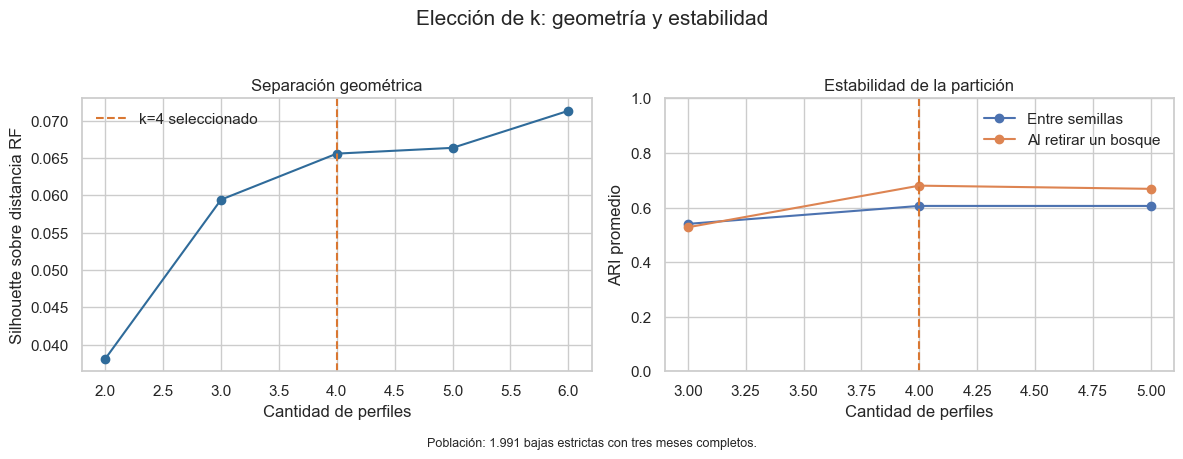

In [16]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
axes[0].plot(evaluacion_k["k"], evaluacion_k["silhouette_rf"], marker="o", color="#2F6B9A")
axes[0].axvline(K_FINAL, color="#D97732", ls="--", label=f"k={K_FINAL} seleccionado")
axes[0].set(title="Separación geométrica", xlabel="Cantidad de perfiles", ylabel="Silhouette sobre distancia RF")
axes[0].legend(frameon=False)

e = estabilidad.set_index("k")
axes[1].plot(e.index, e["ARI_semillas_promedio"], marker="o", label="Entre semillas")
axes[1].plot(e.index, e["ARI_leave_one_forest_promedio"], marker="o", label="Al retirar un bosque")
axes[1].axvline(K_FINAL, color="#D97732", ls="--")
axes[1].set(title="Estabilidad de la partición", xlabel="Cantidad de perfiles", ylabel="ARI promedio", ylim=(0, 1))
axes[1].legend(frameon=False)
fig.suptitle("Elección de k: geometría y estabilidad", fontsize=15)
fig.text(0.5, 0.01, "Población: 1.991 bajas estrictas con tres meses completos.", ha="center", fontsize=9)
fig.tight_layout(rect=[0, 0.03, 1, 0.95])
fig.savefig(OUTPUT_DIR / "03_eleccion_k.png", dpi=160, bbox_inches="tight")
plt.show()


**Decisión.** Se adopta `k=4`. Frente a `k=3`, la ejecución muestra mayor estabilidad entre semillas y al retirar un bosque, sin generar un grupo microscópico; `k=5` separa un grupo de sólo 27 clientes. La mejora de *silhouette* es modesta, por lo que `k=4` no se presenta como un óptimo matemático sino como una solución útil y más estable dentro de las alternativas evaluadas. La sensibilidad a la muestra de continuadores se informa por separado y limita la generalización.


## 14. Etiquetas finales y perfiles de negocio

Los números producidos por el algoritmo no tienen significado comercial. Se renombran mediante reglas verificables: el grupo con mayor uso de payroll se denomina “Vinculados por nómina”; el de menor actividad, “Desvinculación avanzada”; entre los dos restantes, el de más familias activas se denomina “Vinculados multicanal” y el otro “Digitales selectivos”. Los nombres se contrastan luego con la tabla completa de caracterización.


In [17]:
labels_raw = fcluster(linkage_final, t=K_FINAL, criterion="maxclust")
base_clusters = strict_complete.set_index("numero_de_cliente").loc[ids_cluster].reset_index().copy()
base_clusters["cluster_raw"] = labels_raw

base_clusters["payroll_activo"] = (base_clusters["cpayroll_trx"] > 0).astype(int)
base_clusters["usa_tarjeta"] = (base_clusters["tarjetas_transacciones"] > 0).astype(int)
base_clusters["usa_digital"] = (base_clusters["transacciones_digitales"] > 0).astype(int)
base_clusters["emite_transferencias"] = (base_clusters["ctransferencias_emitidas"] > 0).astype(int)
base_clusters["tiene_credito"] = (base_clusters["cantidad_creditos"] > 0).astype(int)
base_clusters["tiene_inversion"] = (base_clusters["cantidad_inversiones"] > 0).astype(int)
base_clusters["tiene_seguro"] = (base_clusters["cantidad_seguros"] > 0).astype(int)
base_clusters["usa_debitos"] = (base_clusters["debitos_automaticos"] > 0).astype(int)
base_clusters["paga_servicios"] = (base_clusters["pagos_servicios"] > 0).astype(int)
base_clusters["saldo_negativo"] = (base_clusters["mcuentas_saldo"] < 0).astype(int)
base_clusters["mantenimiento_positivo"] = (base_clusters["mcomisiones_mantenimiento"] > 0).astype(int)
base_clusters["familias_activas"] = base_clusters[[
    "payroll_activo", "usa_tarjeta", "usa_digital", "emite_transferencias",
    "tiene_credito", "tiene_inversion", "tiene_seguro", "usa_debitos", "paga_servicios",
]].sum(axis=1)

por_raw = base_clusters.groupby("cluster_raw").agg(
    porcentaje_payroll=("payroll_activo", "mean"),
    transacciones=("ctrx_quarter", "median"),
    familias_activas=("familias_activas", "mean"),
    porcentaje_digital=("usa_digital", "mean"),
)
raw_payroll = por_raw["porcentaje_payroll"].idxmax()
raw_desvinculado = por_raw.drop(index=raw_payroll)["transacciones"].idxmin()
raw_restantes = [c for c in por_raw.index if c not in {raw_payroll, raw_desvinculado}]
raw_multicanal = por_raw.loc[raw_restantes, "familias_activas"].idxmax()
raw_digital_selectivo = next(c for c in raw_restantes if c != raw_multicanal)

mapa_perfiles = {
    raw_multicanal: "Vinculados multicanal",
    raw_digital_selectivo: "Digitales selectivos",
    raw_payroll: "Vinculados por nómina",
    raw_desvinculado: "Desvinculación avanzada",
}
codigo_perfil = {nombre: i + 1 for i, nombre in enumerate(PROFILE_ORDER)}
base_clusters["perfil"] = base_clusters["cluster_raw"].map(mapa_perfiles)
base_clusters["cluster_final"] = base_clusters["perfil"].map(codigo_perfil).astype(int)

asignacion_clusters_finales = base_clusters[["numero_de_cliente", "cluster_final", "perfil"]].copy()
assert asignacion_clusters_finales["numero_de_cliente"].is_unique

hash_etiquetas = hashlib.sha256(
    asignacion_clusters_finales.sort_values("numero_de_cliente")["cluster_final"].to_numpy(np.int16).tobytes()
).hexdigest()[:16]
print("Hash de etiquetas finales:", hash_etiquetas)
display(base_clusters.groupby(["cluster_final", "perfil"]).size().rename("clientes").reset_index())


Hash de etiquetas finales: a1a8b756ce522202


,cluster_final,perfil,clientes
0,1,Vinculados multicanal,450
1,2,Digitales selectivos,541
2,3,Vinculados por nómina,104
3,4,Desvinculación avanzada,896


In [19]:
def pct(s):
    return 100 * s.mean()

perfil_general = base_clusters.groupby(["cluster_final", "perfil"], observed=True).agg(
    clientes=("numero_de_cliente", "nunique"),
    edad_mediana=("cliente_edad", "median"),
    antiguedad_mediana=("cliente_antiguedad", "median"),
    productos_mediana=("cproductos", "median"),
    familias_activas_mediana=("familias_activas", "median"),
    transacciones_t0=("ctrx_quarter", "median"),
    transacciones_3m=("ctrx_quarter_media_3", "median"),
    porcentaje_payroll=("payroll_activo", pct),
    porcentaje_usa_tarjeta=("usa_tarjeta", pct),
    porcentaje_digital=("usa_digital", pct),
    porcentaje_transferencias=("emite_transferencias", pct),
    porcentaje_credito=("tiene_credito", pct),
    porcentaje_inversion=("tiene_inversion", pct),
    porcentaje_seguro=("tiene_seguro", pct),
    porcentaje_debitos=("usa_debitos", pct),
    porcentaje_servicios=("paga_servicios", pct),
    saldo_mediano=("mcuentas_saldo", "median"),
    porcentaje_saldo_negativo=("saldo_negativo", pct),
    rentabilidad_mediana=("mrentabilidad", "median"),
).reset_index()
perfil_general["porcentaje_clientes"] = 100 * perfil_general["clientes"] / perfil_general["clientes"].sum()
perfil_general = perfil_general.sort_values("cluster_final")
display(perfil_general.round(2))
n_por_perfil = perfil_general.set_index("perfil")["clientes"].astype(int).to_dict()

composicion_cohorte = pd.crosstab(
    base_clusters["perfil"], base_clusters["foto_mes_ancla"], normalize="index"
).mul(100).reindex(PROFILE_ORDER)
display(composicion_cohorte.round(2).rename_axis(index="perfil", columns="mes de anclaje (%)"))


,cluster_final,perfil,clientes,edad_mediana,antiguedad_mediana,productos_mediana,familias_activas_mediana,transacciones_t0,transacciones_3m,porcentaje_payroll,porcentaje_usa_tarjeta,porcentaje_digital,porcentaje_transferencias,porcentaje_credito,porcentaje_inversion,porcentaje_seguro,porcentaje_debitos,porcentaje_servicios,saldo_mediano,porcentaje_saldo_negativo,rentabilidad_mediana,porcentaje_clientes
0,1,Vinculados multicanal,450,48.00,111.00,7.00,3.00,44.00,44.17,0.89,100.00,91.56,26.44,4.00,8.22,24.67,77.78,17.11,-13.50,51.56,"1,527.61",22.60
1,2,Digitales selectivos,541,46.00,116.00,6.00,3.00,38.00,45.33,1.29,44.73,83.55,39.00,6.28,7.58,18.67,49.54,24.03,"1,626.88",35.86,"1,816.61",27.17
2,3,Vinculados por nómina,104,45.00,62.50,6.00,4.00,57.00,53.67,92.31,45.19,89.42,54.81,12.50,11.54,20.19,47.12,34.62,"5,987.52",27.88,"1,341.96",5.22
3,4,Desvinculación avanzada,896,45.00,65.50,6.00,1.00,5.00,6.00,0.45,12.17,46.88,4.58,9.60,2.12,11.50,15.51,1.12,"-6,512.00",86.27,"1,883.89",45.00


mes de anclaje (%),202105,202106
perfil,,
Vinculados multicanal,51.56,48.44
Digitales selectivos,52.68,47.32
Vinculados por nómina,59.62,40.38
Desvinculación avanzada,61.38,38.62


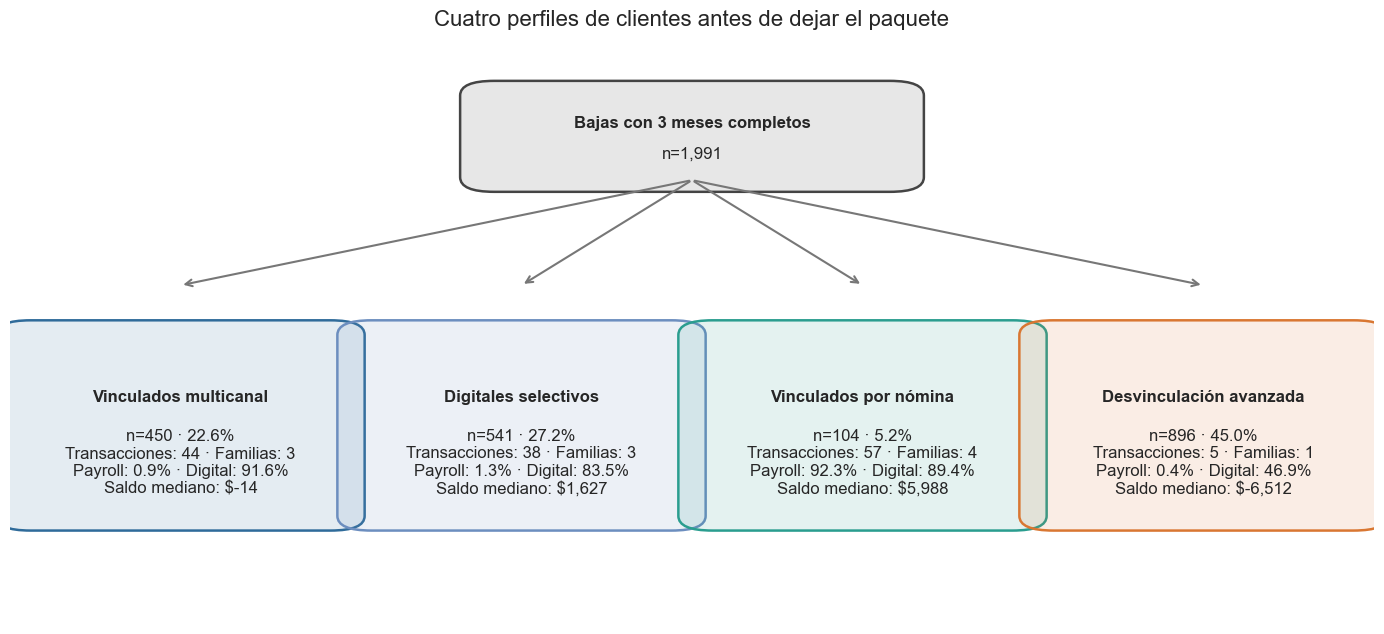

In [20]:
fig, ax = plt.subplots(figsize=(14, 6.5))
ax.axis("off")
caja(ax, 0.35, 0.76, 0.30, 0.15, "Bajas con 3 meses completos", f"n={len(base_clusters):,}", "#444444")

posiciones = np.linspace(0.01, 0.76, len(PROFILE_ORDER))
for i, fila in perfil_general.iterrows():
    x = posiciones[int(fila["cluster_final"])-1]
    color = PROFILE_COLORS[fila["perfil"]]
    ax.annotate("", xy=(x+0.115, 0.58), xytext=(0.50, 0.76), xycoords=ax.transAxes,
                arrowprops=dict(arrowstyle="->", color="#777777", lw=1.5))
    detalle = (
        f"n={int(fila['clientes']):,} · {fila['porcentaje_clientes']:.1f}%\n"
        f"Transacciones: {fila['transacciones_t0']:.0f} · Familias: {fila['familias_activas_mediana']:.0f}\n"
        f"Payroll: {fila['porcentaje_payroll']:.1f}% · Digital: {fila['porcentaje_digital']:.1f}%\n"
        f"Saldo mediano: ${fila['saldo_mediano']:,.0f}"
    )
    caja(ax, x, 0.18, 0.23, 0.32, fila["perfil"], detalle, color)

ax.set_title("Cuatro perfiles de clientes antes de dejar el paquete", fontsize=16, pad=10)
fig.tight_layout()
fig.savefig(OUTPUT_DIR / "04_arbol_perfiles.png", dpi=170, bbox_inches="tight")
plt.show()


## 15. Trayectorias previas y abandono de familias

Las curvas siguientes utilizan exactamente los mismos clientes en `t−2`, `t−1` y `t0`. El denominador permanece constante dentro de cada perfil. Una disminución observada es una trayectoria descriptiva; no permite atribuir la baja a una causa concreta.


In [21]:
filas_trayectoria = []
for _, r in base_clusters.iterrows():
    for etiqueta_mes, sufijo in [("t−2", "lag_2"), ("t−1", "lag_1"), ("t0", None)]:
        def valor(campo):
            return r[campo] if sufijo is None else r[f"{campo}_{sufijo}"]
        filas_trayectoria.append({
            "numero_de_cliente": r["numero_de_cliente"],
            "perfil": r["perfil"],
            "mes_relativo": etiqueta_mes,
            "transacciones": valor("ctrx_quarter"),
            "saldo": valor("mcuentas_saldo"),
            "productos": valor("cproductos"),
            "usa_tarjeta": 100 * (valor("tarjetas_transacciones") > 0),
            "usa_digital": 100 * (valor("transacciones_digitales") > 0),
        })
trayectorias = pd.DataFrame(filas_trayectoria)
orden_meses = ["t−2", "t−1", "t0"]
resumen_trayectorias = trayectorias.groupby(["perfil", "mes_relativo"], observed=True).agg(
    clientes=("numero_de_cliente", "nunique"),
    transacciones=("transacciones", "median"),
    saldo=("saldo", "median"),
    productos=("productos", "median"),
    usa_tarjeta=("usa_tarjeta", "mean"),
    usa_digital=("usa_digital", "mean"),
).reset_index()
resumen_trayectorias["mes_relativo"] = pd.Categorical(resumen_trayectorias["mes_relativo"], orden_meses, ordered=True)
display(resumen_trayectorias.sort_values(["perfil", "mes_relativo"]).round(2))


,perfil,mes_relativo,clientes,transacciones,saldo,productos,usa_tarjeta,usa_digital
2,Desvinculación avanzada,t−2,896,6.00,"-4,474.10",6.00,21.99,44.42
1,Desvinculación avanzada,t−1,896,6.00,"-6,111.32",6.00,16.52,43.19
0,Desvinculación avanzada,t0,896,5.00,"-6,512.00",6.00,12.17,46.88
5,Digitales selectivos,t−2,541,51.00,"9,633.32",7.00,62.29,85.77
4,Digitales selectivos,t−1,541,46.00,"6,635.47",7.00,56.75,83.55
3,Digitales selectivos,t0,541,38.00,"1,626.88",6.00,44.73,83.55
8,Vinculados multicanal,t−2,450,45.00,264.10,7.00,99.56,90.67
7,Vinculados multicanal,t−1,450,45.00,78.98,7.00,99.78,89.33
6,Vinculados multicanal,t0,450,44.00,-13.50,7.00,100.00,91.56
11,Vinculados por nómina,t−2,104,58.50,"3,440.04",7.00,48.08,89.42


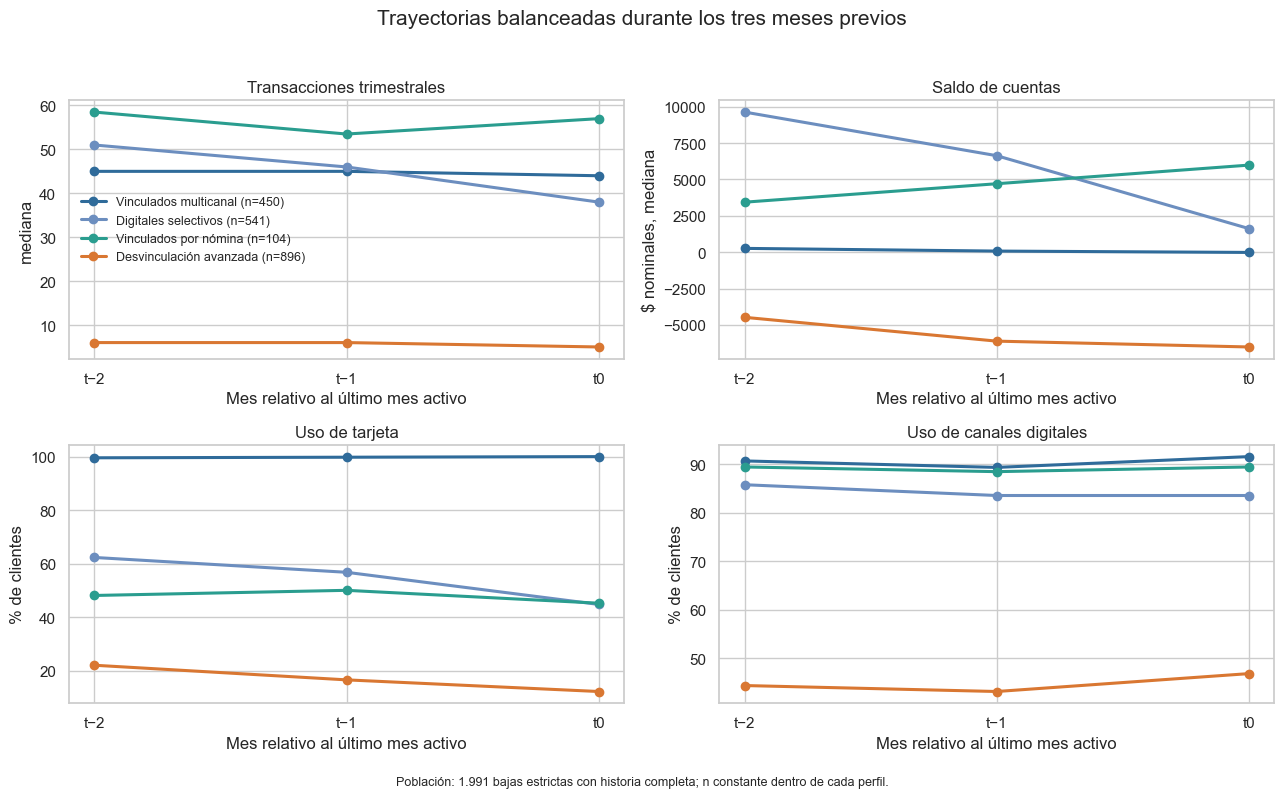

In [22]:
fig, axes = plt.subplots(2, 2, figsize=(13, 8))
metricas = [
    ("transacciones", "Transacciones trimestrales", "mediana"),
    ("saldo", "Saldo de cuentas", "$ nominales, mediana"),
    ("usa_tarjeta", "Uso de tarjeta", "% de clientes"),
    ("usa_digital", "Uso de canales digitales", "% de clientes"),
]
for ax, (col, titulo, ylab) in zip(axes.ravel(), metricas):
    for perfil in PROFILE_ORDER:
        d = resumen_trayectorias[resumen_trayectorias["perfil"] == perfil].sort_values("mes_relativo")
        ax.plot(d["mes_relativo"].astype(str), d[col], marker="o", lw=2.2,
                color=PROFILE_COLORS[perfil], label=f"{perfil} (n={n_por_perfil[perfil]:,})")
    ax.set_title(titulo)
    ax.set_xlabel("Mes relativo al último mes activo")
    ax.set_ylabel(ylab)
axes[0, 0].legend(frameon=False, fontsize=9)
fig.suptitle("Trayectorias balanceadas durante los tres meses previos", fontsize=15)
fig.text(0.5, 0.01, "Población: 1.991 bajas estrictas con historia completa; n constante dentro de cada perfil.", ha="center", fontsize=9)
fig.tight_layout(rect=[0, 0.03, 1, 0.96])
fig.savefig(OUTPUT_DIR / "05_trayectorias.png", dpi=160, bbox_inches="tight")
plt.show()


perfil,Vinculados multicanal,Digitales selectivos,Vinculados por nómina,Desvinculación avanzada
familia,,,,
Canales digitales,4.00,7.95,5.77,13.84
Créditos,3.78,6.65,3.85,3.46
Débitos automáticos,3.33,12.20,5.77,5.80
Inversiones,5.33,8.32,7.69,0.78
Pago de servicios,7.78,10.17,5.77,1.56
Payroll,1.11,11.65,7.69,1.79
Seguros,3.33,4.62,0.96,3.01
Tenencia de tarjeta,0.00,12.57,2.88,13.62
Uso de tarjeta,0.00,19.59,7.69,10.83


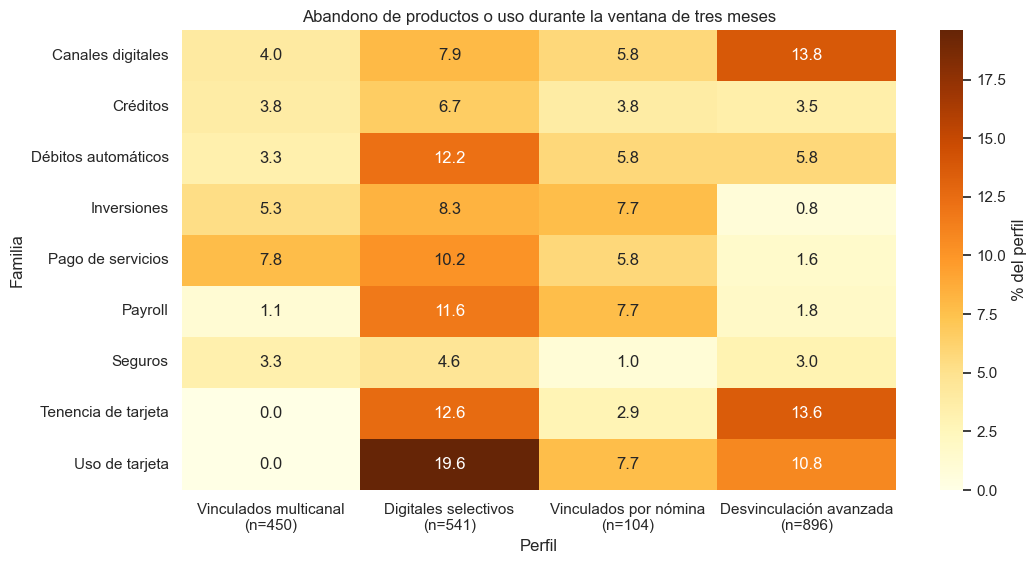

In [23]:
mapa_abandonos = {
    "abandono_cpayroll_trx_3m": "Payroll",
    "abandono_tarjetas_cantidad_3m": "Tenencia de tarjeta",
    "abandono_tarjetas_transacciones_3m": "Uso de tarjeta",
    "abandono_debitos_automaticos_3m": "Débitos automáticos",
    "abandono_pagos_servicios_3m": "Pago de servicios",
    "abandono_transacciones_digitales_3m": "Canales digitales",
    "abandono_cantidad_creditos_3m": "Créditos",
    "abandono_cantidad_inversiones_3m": "Inversiones",
    "abandono_cantidad_seguros_3m": "Seguros",
}
abandono_largo = base_clusters[["perfil"] + list(mapa_abandonos)].melt(
    id_vars="perfil", var_name="variable", value_name="abandono"
)
abandono_largo["familia"] = abandono_largo["variable"].map(mapa_abandonos)
abandono_resumen = abandono_largo.groupby(["perfil", "familia"], observed=True)["abandono"].mean().mul(100).reset_index()

tabla_abandono = abandono_resumen.pivot(index="familia", columns="perfil", values="abandono").reindex(columns=PROFILE_ORDER)
display(tabla_abandono.round(2))

fig, ax = plt.subplots(figsize=(11, 5.8))
sns.heatmap(tabla_abandono, annot=True, fmt=".1f", cmap="YlOrBr", cbar_kws={"label":"% del perfil"}, ax=ax)
ax.set_title("Abandono de productos o uso durante la ventana de tres meses")
ax.set_xlabel("Perfil")
ax.set_ylabel("Familia")
ax.set_xticklabels([f"{p}\n(n={n_por_perfil[p]:,})" for p in PROFILE_ORDER], rotation=0)
fig.tight_layout()
fig.savefig(OUTPUT_DIR / "06_abandono_familias.png", dpi=160, bbox_inches="tight")
plt.show()


**Precaución.** “Perder” un crédito, inversión o seguro también puede reflejar vencimiento o cancelación normal. Estos indicadores describen el cambio observado; no demuestran insatisfacción ni causalidad.


## 16. Valor económico descriptivo

No se presume que rentabilidad, comisiones y márgenes sean componentes aditivos. Primero se audita esa hipótesis. En ausencia de un diccionario contable completo, cada campo se presenta por separado y no se calcula una supuesta “rentabilidad neta sin mantenimiento”.


In [24]:
auditoria_contable = con.execute(
    """
    SELECT
        COUNT(*) AS filas,
        SUM(ABS(mcomisiones-(mcomisiones_mantenimiento+mcomisiones_otras)) < 1e-6) AS identidad_comisiones,
        SUM(ABS(mrentabilidad-(mcomisiones+mactivos_margen+mpasivos_margen)) < 1e-6) AS identidad_rentabilidad,
        MEDIAN(mrentabilidad-(mcomisiones+mactivos_margen+mpasivos_margen)) AS residuo_rentabilidad_mediano,
        MAX(ABS(mrentabilidad-(mcomisiones+mactivos_margen+mpasivos_margen))) AS residuo_rentabilidad_max_abs
    FROM raw
    """
).df()
auditoria_contable["porcentaje_identidad_comisiones"] = 100 * auditoria_contable["identidad_comisiones"] / auditoria_contable["filas"]
auditoria_contable["porcentaje_identidad_rentabilidad"] = 100 * auditoria_contable["identidad_rentabilidad"] / auditoria_contable["filas"]
display(auditoria_contable.round(2))

perfil_economico = base_clusters.groupby(["cluster_final", "perfil"], observed=True).agg(
    clientes=("numero_de_cliente", "nunique"),
    rentabilidad_mensual_mediana=("mrentabilidad", "median"),
    rentabilidad_anual_mediana=("mrentabilidad_annual", "median"),
    comisiones_totales_medianas=("mcomisiones", "median"),
    mantenimiento_mediano=("mcomisiones_mantenimiento", "median"),
    otras_comisiones_medianas=("mcomisiones_otras", "median"),
    margen_activos_mediano=("mactivos_margen", "median"),
    margen_pasivos_mediano=("mpasivos_margen", "median"),
    saldo_mediano=("mcuentas_saldo", "median"),
    porcentaje_saldo_negativo=("saldo_negativo", pct),
    porcentaje_mantenimiento_positivo=("mantenimiento_positivo", pct),
).reset_index().sort_values("cluster_final")
display(perfil_economico.round(2))


,filas,identidad_comisiones,identidad_rentabilidad,residuo_rentabilidad_mediano,residuo_rentabilidad_max_abs,porcentaje_identidad_comisiones,porcentaje_identidad_rentabilidad
0,983061,"642,636.00","2,144.00",31.65,"115,270.69",65.37,0.22


,cluster_final,perfil,clientes,rentabilidad_mensual_mediana,rentabilidad_anual_mediana,comisiones_totales_medianas,mantenimiento_mediano,otras_comisiones_medianas,margen_activos_mediano,margen_pasivos_mediano,saldo_mediano,porcentaje_saldo_negativo,porcentaje_mantenimiento_positivo
0,1,Vinculados multicanal,450,"1,527.61","6,509.34","1,945.22","1,774.04","1,945.22",-556.80,240.40,-13.50,51.56,71.56
1,2,Digitales selectivos,541,"1,816.61","13,396.75","1,598.35","1,774.04","1,598.62",1.05,107.15,"1,626.88",35.86,62.66
2,3,Vinculados por nómina,104,"1,341.96","9,248.92",457.12,0.00,457.12,-1.57,262.65,"5,987.52",27.88,25.96
3,4,Desvinculación avanzada,896,"1,883.89","12,814.70","1,592.20","1,774.04","1,592.20",136.58,1.96,"-6,512.00",86.27,74.89


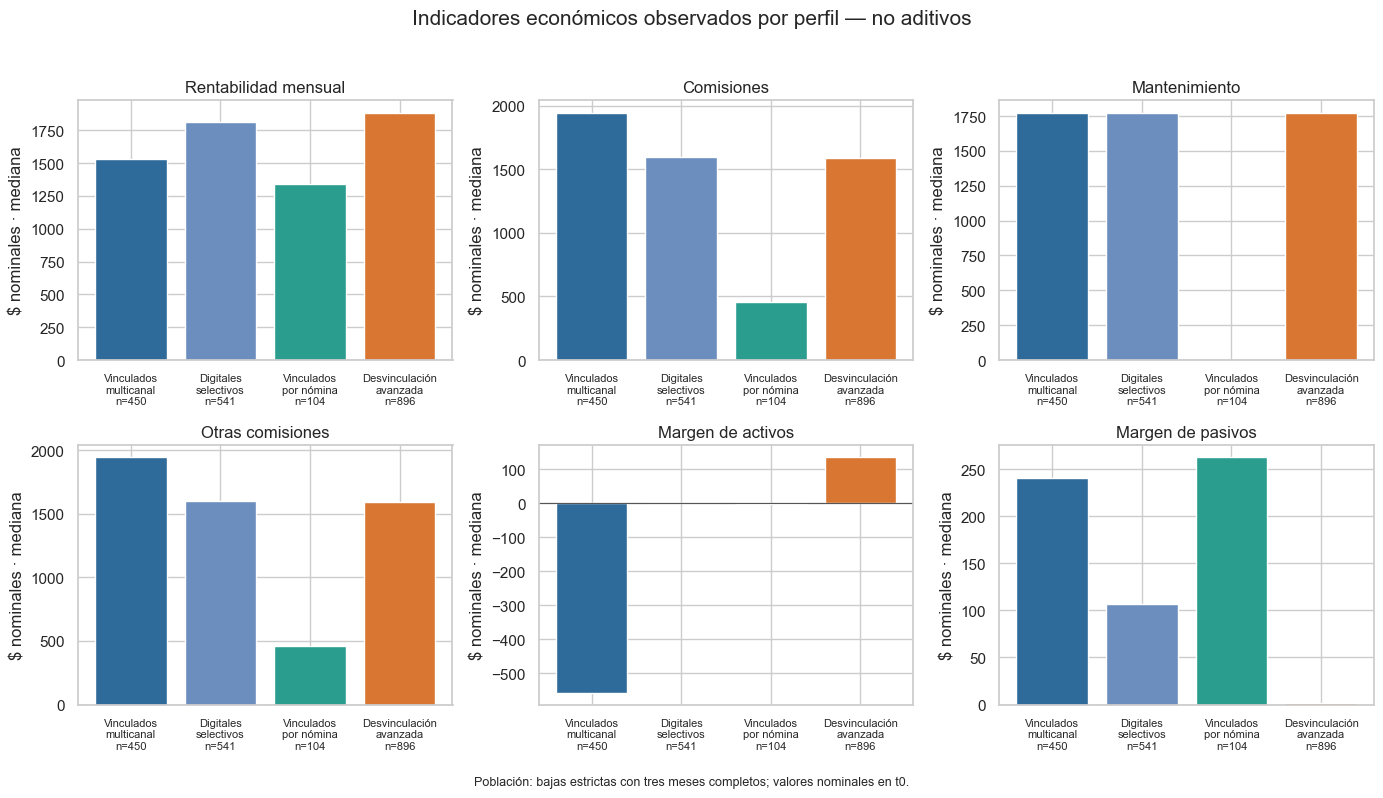

In [25]:
componentes = [
    ("Rentabilidad mensual", "rentabilidad_mensual_mediana"),
    ("Comisiones", "comisiones_totales_medianas"),
    ("Mantenimiento", "mantenimiento_mediano"),
    ("Otras comisiones", "otras_comisiones_medianas"),
    ("Margen de activos", "margen_activos_mediano"),
    ("Margen de pasivos", "margen_pasivos_mediano"),
]
plot_econ = perfil_economico.set_index("perfil").loc[PROFILE_ORDER]
fig, axes = plt.subplots(2, 3, figsize=(14, 8))
for ax, (titulo, col) in zip(axes.ravel(), componentes):
    vals = plot_econ[col]
    ax.bar(range(len(vals)), vals, color=[PROFILE_COLORS[p] for p in vals.index])
    ax.axhline(0, color="#555555", lw=0.8)
    ax.set_xticks(
        range(len(vals)),
        [f"{p.replace(' ', chr(10), 1)}\nn={n_por_perfil[p]:,}" for p in vals.index],
        fontsize=8,
    )
    ax.set_title(titulo)
    ax.set_ylabel("$ nominales · mediana")
fig.suptitle("Indicadores económicos observados por perfil — no aditivos", fontsize=15)
fig.text(0.5, 0.01, "Población: bajas estrictas con tres meses completos; valores nominales en t0.", ha="center", fontsize=9)
fig.tight_layout(rect=[0, 0.03, 1, 0.96])
fig.savefig(OUTPUT_DIR / "07_economia_descriptiva.png", dpi=160, bbox_inches="tight")
plt.show()


**Interpretación.** La rentabilidad registrada puede coexistir con saldos negativos, crédito o cargos. Esto no equivale automáticamente a una relación económica sana ni a valor futuro. La evidencia disponible permite priorizar experimentos, pero no estimar todavía rentabilidad incremental, riesgo, costo de subsidio o punto de equilibrio.


## 17. Generalización a historia parcial

Los perfiles se observan directamente en 1.991 bajas. Para las 1.986 restantes se estima el perfil compatible a partir de `t0`. Las etiquetas observadas nunca se reemplazan. La validación por mes mide fidelidad respecto de una taxonomía construida conjuntamente con mayo y junio; no es una validación causal ni completamente inductiva.


In [26]:
FEATURES_EXTENSION = features_actuales
X_extension = base_clusters[FEATURES_EXTENSION].replace([np.inf, -np.inf], np.nan)
y_extension = base_clusters["cluster_final"].astype(int)
mes_extension = base_clusters["foto_mes_ancla"].astype(int)

modelo_extension = Pipeline([
    ("imputacion", SimpleImputer(strategy="median", add_indicator=True)),
    ("bosque", RandomForestClassifier(
        n_estimators=500, min_samples_leaf=10, max_features="sqrt",
        class_weight="balanced", n_jobs=-1, random_state=214363,
    )),
])

logo = LeaveOneGroupOut()
pred_fuera_mes = cross_val_predict(
    modelo_extension, X_extension, y_extension,
    groups=mes_extension, cv=logo, method="predict",
)
metricas_extension = pd.DataFrame([{
    "balanced_accuracy": balanced_accuracy_score(y_extension, pred_fuera_mes),
    "f1_macro": f1_score(y_extension, pred_fuera_mes, average="macro"),
}])
display(metricas_extension.round(4))
display(pd.DataFrame(classification_report(y_extension, pred_fuera_mes, output_dict=True, zero_division=0)).T.round(3))

modelo_extension.fit(X_extension, y_extension)
strict_all["cluster_predicho_t0"] = modelo_extension.predict(strict_all[FEATURES_EXTENSION])
prob_strict = modelo_extension.predict_proba(strict_all[FEATURES_EXTENSION])
strict_all["confianza_prediccion"] = prob_strict.max(axis=1)

strict_extended = strict_all.merge(
    asignacion_clusters_finales[["numero_de_cliente", "cluster_final", "perfil"]],
    on="numero_de_cliente", how="left", validate="one_to_one",
)
strict_extended["origen_cluster"] = np.where(strict_extended["cluster_final"].notna(), "observado_3m", "proyectado_t0")
strict_extended["cluster_analisis"] = strict_extended["cluster_final"].fillna(strict_extended["cluster_predicho_t0"]).astype(int)
nombre_por_codigo = {v: k for k, v in codigo_perfil.items()}
strict_extended["perfil_analisis"] = strict_extended["cluster_analisis"].map(nombre_por_codigo)

resumen_extension = strict_extended.groupby(["origen_cluster", "perfil_analisis"], observed=True).agg(
    clientes=("numero_de_cliente", "nunique"),
    confianza_mediana=("confianza_prediccion", "median"),
).reset_index()
resumen_extension["porcentaje"] = 100 * resumen_extension["clientes"] / resumen_extension.groupby("origen_cluster")["clientes"].transform("sum")
display(resumen_extension.round(2))


,balanced_accuracy,f1_macro
0,0.89,0.89


,precision,recall,f1-score,support
1,0.86,0.95,0.90,450.00
2,0.82,0.80,0.81,541.00
3,0.94,0.91,0.93,104.00
4,0.95,0.92,0.94,896.00
accuracy,0.89,0.89,0.89,0.89
macro avg,0.89,0.90,0.89,"1,991.00"
weighted avg,0.89,0.89,0.89,"1,991.00"


,origen_cluster,perfil_analisis,clientes,confianza_mediana,porcentaje
0,observado_3m,Desvinculación avanzada,896,0.89,45.00
1,observado_3m,Digitales selectivos,541,0.73,27.17
2,observado_3m,Vinculados multicanal,450,0.85,22.60
3,observado_3m,Vinculados por nómina,104,0.87,5.22
4,proyectado_t0,Desvinculación avanzada,867,0.89,43.66
5,proyectado_t0,Digitales selectivos,533,0.70,26.84
6,proyectado_t0,Vinculados multicanal,504,0.80,25.38
7,proyectado_t0,Vinculados por nómina,82,0.80,4.13


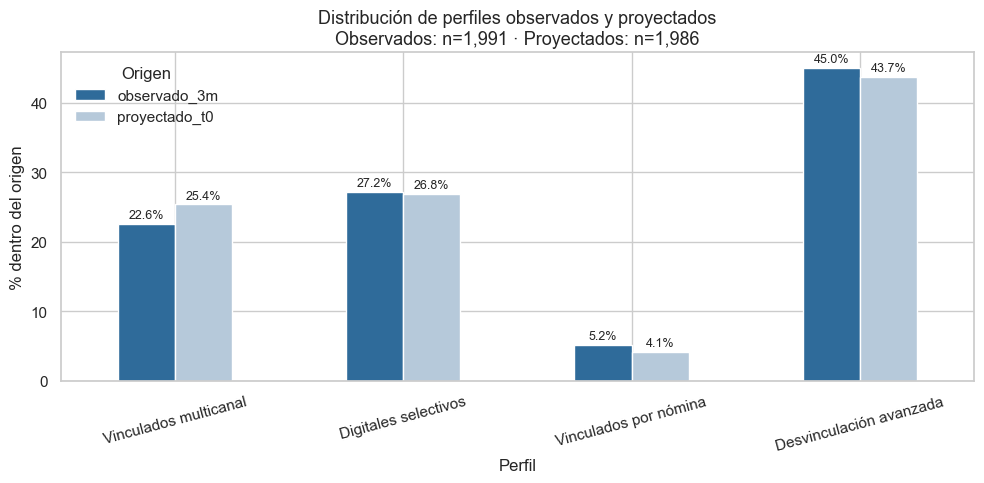

In [27]:
fig, ax = plt.subplots(figsize=(10, 5))
tmp = resumen_extension.pivot(index="perfil_analisis", columns="origen_cluster", values="porcentaje").reindex(PROFILE_ORDER)
tmp.plot(kind="bar", ax=ax, color=["#2F6B9A", "#B6C9DA"])
ax.set_title(
    "Distribución de perfiles observados y proyectados\n"
    f"Observados: n={len(base_clusters):,} · Proyectados: n={len(strict_all)-len(base_clusters):,}",
    fontsize=13,
)
ax.set_xlabel("Perfil")
ax.set_ylabel("% dentro del origen")
ax.legend(title="Origen", frameon=False)
ax.tick_params(axis="x", rotation=15)
for contenedor in ax.containers:
    ax.bar_label(contenedor, fmt="%.1f%%", padding=2, fontsize=9)
fig.tight_layout()
fig.savefig(OUTPUT_DIR / "08_observado_proyectado.png", dpi=160, bbox_inches="tight")
plt.show()


## 18. Sensibilidad con censurados

Se realizan dos comprobaciones diferentes:

1. **Compatibilidad:** asignar a todos los censurados uno de los perfiles ya definidos.
2. **Sensibilidad estructural:** incorporar censurados con tres meses completos a la matriz de proximidad, repetir el clustering y medir cuánto cambia la partición de las bajas estrictas compartidas.

La segunda prueba sí permite detectar una alteración de la estructura; la primera, por construcción, no puede crear perfiles nuevos.


In [28]:
sensibilidad_t0 = con.execute(
    """
    SELECT
        e.numero_evento, e.ultimo_mes_activo AS foto_mes_ancla,
        e.primer_mes_ausente, e.poblacion,
        f.* EXCLUDE (foto_mes)
    FROM eventos_baja e
    JOIN fe_panel f ON e.numero_de_cliente=f.numero_de_cliente
                   AND e.ultimo_mes_activo=f.foto_mes
    WHERE e.poblacion IN ('censurada','intermitente')
    ORDER BY poblacion, foto_mes_ancla, f.numero_de_cliente
    """
).df()
sensibilidad_t0["historia_3m_completa"] = (
    (sensibilidad_t0["observaciones_hasta_mes"] >= 3)
    & (sensibilidad_t0["salto_1"] == 1)
    & (sensibilidad_t0["salto_2"] == 2)
).astype(int)
sensibilidad_t0["cluster_compatible"] = modelo_extension.predict(sensibilidad_t0[FEATURES_EXTENSION])
sensibilidad_t0["perfil_compatible"] = sensibilidad_t0["cluster_compatible"].map(nombre_por_codigo)

distribucion_sensibilidad = sensibilidad_t0.groupby(["poblacion", "perfil_compatible"], observed=True).size().rename("clientes").reset_index()
distribucion_sensibilidad["porcentaje"] = 100 * distribucion_sensibilidad["clientes"] / distribucion_sensibilidad.groupby("poblacion")["clientes"].transform("sum")
display(distribucion_sensibilidad.round(2))

cens_complete = sensibilidad_t0[(sensibilidad_t0["poblacion"] == "censurada") & (sensibilidad_t0["historia_3m_completa"] == 1)].copy()
combined_complete = pd.concat([base_clusters, cens_complete], ignore_index=True, sort=False)
combined_complete = combined_complete.sort_values("numero_de_cliente", kind="mergesort").reset_index(drop=True)

proximidades_ampliadas = []
for modelo in rf_models:
    hojas = modelo.apply(combined_complete[FEATURES_RF].astype(np.float32))
    proximidades_ampliadas.append(matriz_proximidad(hojas))
P_ampliada = np.mean(proximidades_ampliadas, axis=0, dtype=np.float64)
Z_ampliada = linkage(squareform(np.clip(1-P_ampliada,0,1), checks=False), method="average")
labels_ampliadas = fcluster(Z_ampliada, t=K_FINAL, criterion="maxclust")
combined_complete["cluster_ampliado_raw"] = labels_ampliadas

labels_estrictas_ampliadas = combined_complete.loc[
    combined_complete["numero_de_cliente"].isin(base_clusters["numero_de_cliente"]),
    ["numero_de_cliente", "cluster_ampliado_raw"],
].set_index("numero_de_cliente").loc[ids_cluster, "cluster_ampliado_raw"].to_numpy()

ari_censura_estructural = adjusted_rand_score(labels_raw, labels_estrictas_ampliadas)
resumen_censura_estructural = pd.DataFrame([{
    "estrictas_completas": len(base_clusters),
    "censuradas_completas": len(cens_complete),
    "ARI_estrictas_antes_despues": ari_censura_estructural,
    "tamanios_clustering_ampliado": sorted(pd.Series(labels_ampliadas).value_counts().tolist(), reverse=True),
}])
display(resumen_censura_estructural.round(4))

if ari_censura_estructural < 0.60:
    display(Markdown(
        "**Resultado de sensibilidad:** al incorporar censurados la estructura cambia de forma "
        f"material (ARI={ari_censura_estructural:.2f}). Los perfiles principales describen con utilidad "
        "a las bajas estrictas, pero no deben presentarse como una taxonomía universal o estable fuera de esa población."
    ))
else:
    display(Markdown(
        f"**Resultado de sensibilidad:** la estructura conserva una concordancia sustantiva (ARI={ari_censura_estructural:.2f}) "
        "al incorporar censurados, aunque esos casos no se reclasifican como bajas confirmadas."
    ))


,poblacion,perfil_compatible,clientes,porcentaje
0,censurada,Desvinculación avanzada,473,42.88
1,censurada,Digitales selectivos,297,26.93
2,censurada,Vinculados multicanal,285,25.84
3,censurada,Vinculados por nómina,48,4.35
4,intermitente,Desvinculación avanzada,3,13.04
5,intermitente,Digitales selectivos,2,8.70
6,intermitente,Vinculados multicanal,13,56.52
7,intermitente,Vinculados por nómina,5,21.74


,estrictas_completas,censuradas_completas,ARI_estrictas_antes_despues,tamanios_clustering_ampliado
0,1991,1097,0.49,"[2036, 809, 204, 39]"


**Resultado de sensibilidad:** al incorporar censurados la estructura cambia de forma material (ARI=0.49). Los perfiles principales describen con utilidad a las bajas estrictas, pero no deben presentarse como una taxonomía universal o estable fuera de esa población.

## 19. Intermitentes: desaparición y regreso

Los intermitentes no se consideran bajas permanentes. Debido a su tamaño reducido, se informan como casos observados y no como evidencia estadística. Además de su perfil compatible, se compara su última observación antes de la ausencia con la primera observación posterior al regreso.


In [29]:
intermitentes_cambio = con.execute(
    """
    WITH eventos AS (
        SELECT * FROM eventos_baja WHERE poblacion='intermitente'
    ),
    retorno AS (
        SELECT e.numero_de_cliente, e.numero_evento, MIN(r.foto_mes) AS primer_mes_retorno
        FROM eventos e JOIN raw r ON e.numero_de_cliente=r.numero_de_cliente
        WHERE r.foto_mes > e.primer_mes_ausente
        GROUP BY 1,2
    )
    SELECT
        e.numero_de_cliente, e.ultimo_mes_activo, e.primer_mes_ausente,
        t.primer_mes_retorno,
        cal_retorno.indice_mes-cal_ausencia.indice_mes AS meses_ausente,
        despues.ctrx_quarter-antes.ctrx_quarter AS cambio_transacciones,
        despues.cproductos-antes.cproductos AS cambio_productos,
        despues.mcuentas_saldo-antes.mcuentas_saldo AS cambio_saldo,
        despues.mrentabilidad-antes.mrentabilidad AS cambio_rentabilidad
    FROM eventos e
    JOIN retorno t USING (numero_de_cliente, numero_evento)
    JOIN calendario cal_ausencia ON e.primer_mes_ausente=cal_ausencia.foto_mes
    JOIN calendario cal_retorno ON t.primer_mes_retorno=cal_retorno.foto_mes
    JOIN raw antes ON e.numero_de_cliente=antes.numero_de_cliente AND e.ultimo_mes_activo=antes.foto_mes
    JOIN raw despues ON e.numero_de_cliente=despues.numero_de_cliente AND t.primer_mes_retorno=despues.foto_mes
    ORDER BY e.numero_de_cliente
    """
).df()

resumen_intermitentes = pd.DataFrame({
    "casos": [len(intermitentes_cambio)],
    "meses_ausencia_mediana": [intermitentes_cambio["meses_ausente"].median()],
    "cambio_transacciones_mediano": [intermitentes_cambio["cambio_transacciones"].median()],
    "cambio_productos_mediano": [intermitentes_cambio["cambio_productos"].median()],
    "cambio_saldo_mediano": [intermitentes_cambio["cambio_saldo"].median()],
    "cambio_rentabilidad_mediano": [intermitentes_cambio["cambio_rentabilidad"].median()],
})
display(resumen_intermitentes.round(2))
display(distribucion_sensibilidad[distribucion_sensibilidad["poblacion"]=="intermitente"].round(2))


,casos,meses_ausencia_mediana,cambio_transacciones_mediano,cambio_productos_mediano,cambio_saldo_mediano,cambio_rentabilidad_mediano
0,23,1.00,-9.00,1.00,69.66,-436.09


,poblacion,perfil_compatible,clientes,porcentaje
4,intermitente,Desvinculación avanzada,3,13.04
5,intermitente,Digitales selectivos,2,8.70
6,intermitente,Vinculados multicanal,13,56.52
7,intermitente,Vinculados por nómina,5,21.74


## 20. Recomendaciones preliminares

Las acciones siguientes traducen asociaciones observadas en hipótesis experimentales. No se afirma que una intervención vaya a evitar la baja sin una prueba controlada.

| Perfil | Evidencia que debe verificarse en la ejecución | Acción preliminar | Riesgo a controlar |
|---|---|---|---|
| **Vinculados multicanal** | Alta actividad, uso de tarjetas y canales; conservan una relación operativa | Contacto temprano para identificar fricción, revisión de cambios recientes y oferta personalizada | Subsidiar clientes que habrían permanecido sin incentivo |
| **Digitales selectivos** | Uso digital relevante con menor amplitud de familias que el perfil multicanal | Mensaje digital breve sobre la función o beneficio efectivamente utilizado; prueba de oferta acotada | Confundir uso digital con alta vinculación económica |
| **Vinculados por nómina** | Relación salarial y uso activo; grupo pequeño pero reconocible | Priorizar continuidad de acreditación, beneficios ligados a nómina y atención rápida | Confundir aguinaldo o reclasificación estacional con relación permanente |
| **Desvinculación avanzada** | Actividad baja, menor uso y mayor deterioro de saldo | Diagnóstico digital de bajo costo; reservar incentivos para casos con valor o recuperación plausible | Financiar masivamente relaciones ya deterioradas o de riesgo |

Para convertir estas recomendaciones en decisiones se necesitan costo por contacto, incentivo, margen futuro, riesgo y efecto incremental de la campaña. El punto de equilibrio mínimo es:

\[
\text{efectividad mínima} = \frac{\text{costo por cliente tratado}}
{\text{valor incremental esperado de una retención}}
\]


## 21. Limitaciones

- Sólo se observan seis meses.
- La baja es ausencia del panel, no cancelación contractual observada.
- Julio queda censurado porque septiembre no está disponible.
- La población se interpreta como Premium por el contexto de la consigna; no existe una variable de paquete que lo demuestre.
- Inflación, aguinaldo, calendario y cambios de cohorte pueden afectar importes nominales.
- No se dispone de un diccionario contable suficiente para descomponer rentabilidad.
- Clustering describe segmentos; no demuestra causalidad ni retenibilidad.
- La partición es sensible a la selección de continuadores y a incorporar censurados; requiere validación con más meses.
- La proyección a historia parcial es una aproximación y conserva su origen.
- La validación de extensión dispone únicamente de mayo y junio.
- Los 23 intermitentes son insuficientes para generalizaciones estadísticas.


## 22. Conclusiones para Miranda

El resultado principal no es una métrica geométrica, sino la existencia de comportamientos comercialmente diferentes antes de la salida. La ejecución siguiente completa automáticamente sus tamaños y evidencia:


In [30]:
lineas = ["### Síntesis ejecutiva de la ejecución", ""]
for _, r in perfil_general.sort_values("cluster_final").iterrows():
    if r["perfil"] == "Vinculados multicanal":
        accion = "priorizar un piloto de contacto personalizado y diagnóstico de fricción"
    elif r["perfil"] == "Digitales selectivos":
        accion = "probar una comunicación digital acotada sobre el uso que todavía conserva"
    elif r["perfil"] == "Vinculados por nómina":
        accion = "probar una intervención específica de continuidad de nómina y beneficios"
    else:
        accion = "evitar subsidios masivos y seleccionar sólo casos con recuperación plausible"
    lineas.append(
        f"- **{r['perfil']}**: {int(r['clientes']):,} clientes "
        f"({r['porcentaje_clientes']:.1f}%). Mediana de {r['transacciones_t0']:.0f} transacciones, "
        f"{r['porcentaje_payroll']:.1f}% con payroll y saldo mediano ${r['saldo_mediano']:,.0f}; "
        f"se propone {accion}."
    )
lineas.extend([
    "",
    f"La población principal contiene **{len(strict_all):,} bajas estrictas**. "
    f"Los perfiles se observan directamente en **{len(base_clusters):,}** clientes y se proyectan, "
    f"con origen explícito, a los **{len(strict_all)-len(base_clusters):,}** restantes.",
    "",
    "Las acciones son decisiones preliminares para experimentar. La evidencia disponible no permite afirmar qué causa la baja ni cuánto valor incremental generará una campaña.",
    f"La sensibilidad a la selección de continuadores produce ARI entre "
    f"{sensibilidad_controles['ARI_con_solucion_final'].min():.2f} y "
    f"{sensibilidad_controles['ARI_con_solucion_final'].max():.2f}.",
    f"La sensibilidad estructural con censurados arroja ARI={ari_censura_estructural:.2f}; "
    "por lo tanto, la taxonomía debe interpretarse dentro de la población principal y validarse con más meses.",
])
display(Markdown("\n".join(lineas)))


### Síntesis ejecutiva de la ejecución

- **Vinculados multicanal**: 450 clientes (22.6%). Mediana de 44 transacciones, 0.9% con payroll y saldo mediano $-14; se propone priorizar un piloto de contacto personalizado y diagnóstico de fricción.
- **Digitales selectivos**: 541 clientes (27.2%). Mediana de 38 transacciones, 1.3% con payroll y saldo mediano $1,627; se propone probar una comunicación digital acotada sobre el uso que todavía conserva.
- **Vinculados por nómina**: 104 clientes (5.2%). Mediana de 57 transacciones, 92.3% con payroll y saldo mediano $5,988; se propone probar una intervención específica de continuidad de nómina y beneficios.
- **Desvinculación avanzada**: 896 clientes (45.0%). Mediana de 5 transacciones, 0.4% con payroll y saldo mediano $-6,512; se propone evitar subsidios masivos y seleccionar sólo casos con recuperación plausible.

La población principal contiene **3,977 bajas estrictas**. Los perfiles se observan directamente en **1,991** clientes y se proyectan, con origen explícito, a los **1,986** restantes.

Las acciones son decisiones preliminares para experimentar. La evidencia disponible no permite afirmar qué causa la baja ni cuánto valor incremental generará una campaña.
La sensibilidad a la selección de continuadores produce ARI entre 0.45 y 0.49.
La sensibilidad estructural con censurados arroja ARI=0.49; por lo tanto, la taxonomía debe interpretarse dentro de la población principal y validarse con más meses.

## 23. Guion resumido para un video de cinco minutos

**0:00–0:35 — Problema.** Se analizaron clientes que dejaron de aparecer en el paquete Premium. Se separaron bajas confirmadas dentro de la ventana, casos censurados e intermitentes.

**0:35–1:05 — Evidencia general.** Antes de la ausencia, las bajas presentan menos actividad, menor uso de productos y una posición de saldo más débil que clientes que continúan en el mismo mes.

**1:05–3:20 — Cuatro perfiles.** Presentar el árbol de perfiles y describir para cada uno tamaño, uso, trayectoria y evidencia económica observada. Evitar explicar Random Forest, linkage o silhouette.

**3:20–4:25 — Decisiones.** Proponer pilotos diferenciados: contacto personalizado para vinculados multicanal; comunicación digital acotada para digitales selectivos; continuidad de nómina para vinculados por payroll; selección estricta y bajo costo para desvinculación avanzada.

**4:25–5:00 — Cierre.** Aclarar que las acciones son hipótesis. El próximo paso es un experimento controlado que mida retención incremental, costo, riesgo y punto de equilibrio.


## 24. Trazabilidad y anexo técnico

### Cambios frente a `EDA.ipynb`

- Se conserva intacto el notebook original.
- Se ordenan determinísticamente las filas antes del bosque.
- Se reemplaza el perfil del “último split” por proximidad real de Random Forest.
- Se promedian cinco bosques y se prueba sensibilidad a semillas y controles.
- Se utiliza una sola matriz, una sola precisión y un solo linkage.
- Se adopta `k=4` por su estabilidad relativa, tamaño e interpretación; no se lo denomina óptimo matemático.
- Se eliminan las conclusiones económicas basadas en aditividad no demostrada.
- Se balancean las trayectorias y se muestran denominadores.
- Se separan etiquetas observadas, proyectadas y compatibles.
- La sensibilidad con censurados incluye una repetición estructural del clustering.
- Las conclusiones y recomendaciones se reescriben desde los resultados reproducibles.

### Solución más parsimoniosa `k=3`

La solución de tres perfiles fusiona dos comportamientos de actividad intermedia. Se conserva para mostrar que la elección de cuatro perfiles agrega detalle comercial, aunque la estabilidad frente a la selección de continuadores continúa siendo una limitación.


In [31]:
labels_k3 = fcluster(linkage_final, t=3, criterion="maxclust")
anexo_k3 = base_clusters[["numero_de_cliente", "ctrx_quarter", "mcuentas_saldo", "mcomisiones_mantenimiento"]].copy()
anexo_k3["cluster_k3_raw"] = labels_k3
resumen_k3 = anexo_k3.groupby("cluster_k3_raw").agg(
    clientes=("numero_de_cliente", "nunique"),
    transacciones_mediana=("ctrx_quarter", "median"),
    saldo_mediano=("mcuentas_saldo", "median"),
    mantenimiento_mediano=("mcomisiones_mantenimiento", "median"),
).reset_index()
display(resumen_k3.round(2))

print("Objetos finales congelados:")
print("  proximidad_final:", proximidad_final.shape, hash_perfiles)
print("  linkage_final:", linkage_final.shape)
print("  asignacion_clusters_finales:", len(asignacion_clusters_finales), "clientes, hash", hash_etiquetas)
print("  RF seeds:", RF_SEEDS)


,cluster_k3_raw,clientes,transacciones_mediana,saldo_mediano,mantenimiento_mediano
0,1,104,57.00,"5,987.52",0.00
1,2,896,5.00,"-6,512.00","1,774.04"
2,3,991,40.00,151.59,"1,774.04"


Objetos finales congelados:
  proximidad_final: (1991, 1991) 9681de68cab1b9de
  linkage_final: (1990, 4)
  asignacion_clusters_finales: 1991 clientes, hash a1a8b756ce522202
  RF seeds: [214363, 42, 2026, 12345, 987654]
